# Case 1 — Payment Routing: Is One Gateway Truly Better, and Does Dynamic Routing Beat Fixed Rules?

**Reference:** Case Study 1 — *Juspay: Maximising Payment Success Rate with Dynamic Gateway Routing* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Payments, Payments Operations, Merchant Success
**Data:** ⚠️ **SYNTHETIC.** No public gateway-level routing dataset exists (see Section 4 and `decision.md` D-1-01). All numbers below come from a simulation calibrated to the figures Juspay published. They are *not* Juspay's data.
**Reproducibility:** seed = 42 everywhere. Run top-to-bottom with `python -m nbconvert --to notebook --execute --inplace 01_payment_routing_success_rate.ipynb`.

## 0. Executive Summary for Business

*(Written last; based on synthetic data calibrated to Juspay's published figures.)*

- **The problem:** today, fixed routing rules split about 4.2 lakh payments a month across 4 gateways without ever learning which gateway works best for whom. **17% of payments fail.** Every 1 percentage point of success rate is worth about ₹80 lakh of monthly order value for this merchant group.
- **There is no single "best gateway".** The top two (PG_C 84.0%, PG_B 83.9%) are statistically tied. The winner depends on the customer's bank: PG_B for SBI, PG_C for HDFC and ICICI. One gateway, **PG_D, is clearly worse on cards (−6 to −7 pp)**, almost entirely because customers fail its OTP / 3-D Secure step.
- **A learning router beats today's rules.** In a like-for-like replay, Thompson Sampling raised success from **82.7% to 83.7% (+0.91 pp, 95% CI +0.87 to +0.96 pp)**. That is a 1.1% relative gain, in line with Juspay's documented "up to 1.15%". It won on all 30 days and protected sales during a 2.5-hour gateway outage (75% vs 67% success).
- **₹ impact:** about **3,800 extra successful payments and ₹41 lakh of net order value a month** (range ₹16–60 lakh), or about ₹9.8 crore a month per crore payments at portfolio scale.
- **Outages can be caught in 15 minutes** with a simple control chart on success rate. The router should use it as a circuit breaker, because on its own it takes about 30 minutes to react and recovers slowly.
- **Cautions:** the data is simulated, so the exact ₹ figure is a planning estimate, not a forecast. If we check a live test every day and stop early, the chance of a false win rises from 5% to 27%. The test must be read once, at a pre-agreed size.
- **I recommend:** apply 4 proven segment rules now, deploy the outage alarm, then run a **14-day, 50/50 A/B test (≈ 89,000 payments per arm)** of the learning router before rolling it out with a permanent rules holdout.

## 1. The Problem in Simple English

Picture a customer in Pune buying a ₹1,800 pair of shoes during the Diwali sale. They tap *Pay*. Behind the scenes, the merchant's payment orchestrator has to choose which **payment gateway** (the company that connects the merchant to the customer's bank or UPI app) carries this payment. Today that choice follows **fixed rules** written months ago: "send 40% of UPI to Gateway A, 35% to Gateway B…", or "send cards to the cheaper gateway".

What goes wrong today:

- **Gateways are not equally good everywhere.** One gateway may be excellent for SBI customers and weak for HDFC customers. A fixed rule cannot see this.
- **Gateways have bad hours.** When a gateway degrades or goes down, a fixed rule keeps sending it traffic until someone notices and edits the rule manually.
- **Every failed payment costs money.** The customer may give up, retry on another site, or call support. At our simulated scale of about 4.2 lakh payments a month, every **1 percentage point** of success rate is about **4,200 payments** and roughly **₹80 lakh of order value** each month.

Who is affected: the **merchant** loses sales, the **customer** gets a frustrating "payment failed" screen (and sometimes a debit that is refunded days later), and the **orchestrator** loses take-rate revenue and merchant trust.

The business wants answers to three questions:

1. Is one gateway *truly* better, or are the differences we see just noise?
2. If differences exist, *for which payment methods and banks*?
3. Would **dynamic routing**, which learns continuously and sends each payment to the gateway most likely to succeed *right now*, beat today's fixed rules, and by how much in ₹?

## 2. Reference from the Case File

### (a) What Juspay actually did — *documented* (quoted from the reference file)

| Item | Documented fact |
|---|---|
| Business problem | "Static rule-based routing fails to adapt when a gateway degrades. Pushing all traffic to the 'best' gateway starves the others of data, so the team cannot tell when they recover." |
| Business question | "Which gateway should *this* transaction go to, right now, to maximise the probability of success? And how fast can a gateway outage be detected and routed around?" |
| Data | Transaction outcomes per gateway; gateway health (latency, downtime); routing dimensions (merchant ID, platform, payment instrument, card network, card BIN) |
| Statistics | "SR is modelled as a **binomial proportion**, approximated as normal, and gateways are compared with **Z-scores**". Worked example: "about 1,104 transactions in a 2-hour window". "Exploration traffic of 5–10%". Toy example: "two gateways at about 80% and 81% SR give 80.655% under optimised allocation vs 80.5% under random allocation." |
| ML | "Non-stationary **multi-armed bandit** with delayed feedback", plus a "control-theoretic (PID-inspired) feedback loop with an exponentially decaying health score" for downtime |
| Validation | "21-day production comparison against rule-based routing" |
| Impact | "Improvement of up to **1.15%** in success rate over traditional rule-based routing. 21-day average: **83.19%** dynamic vs **82.60%** rule-based." "About 2% gain in UPI and up to 7% in some card categories." "In one 2.5-hour outage, about 8,000 transactions were rerouted, recovering about **$15,000 GMV** for a single merchant. Downtime was detected 'within a minute'." Decision latency "about 5 ms". |
| Adoption | "95%+ merchants use rule-based ordering", so ML routing is optional, not a forced default. |

Related, from **Case Study 2 (Cashfree)**: one processor's success-rate gap "was due to 'higher authentication failures', while authorisation declines were about equal". The fix was to split the flow by stage, which gave a "2% increase in success rate".

**Sources:**
- Agrawal & Patil, *A Control-Theoretic Approach to Dynamic Payment Routing for Success Rate Optimization*, arXiv:2510.16735 (Oct 2025) — https://arxiv.org/abs/2510.16735
- Juspay blog, *Juspay Orchestrator and Merchant-Controlled Routing Engine* (Jan 2025) — https://juspay.io/blog/juspay-orchestrator-and-merchant-controlled-routing-engine
- Open-source decision engine — https://github.com/juspay/decision-engine
- Cashfree blog, *Reduce card declines via smart routing* (1 Apr 2025) — https://www.cashfree.com/blog/reduce-card-decline-via-smart-routing/

### (b) What *we* are simulating or adding — *our professional approach*

| Item | Our choice |
|---|---|
| Data | 30 days (1–30 Oct 2025: Navratri → Dussehra → Diwali), about 4.2 lakh synthetic transactions, 4 gateways, 120 merchants. Calibrated so that rule-based SR ≈ 82.6% and gateway gaps are about 1 pp. |
| Built-in patterns | gateway × bank and gateway × method interactions; night-time and festive-day SR dips; a 2.5-hour outage on PG_B (17 Oct, 19:00–21:30); authentication vs authorisation failure split; skewed ₹ amounts; data-quality defects |
| Statistics added | Wilson CIs, two-proportion Z-test + Cohen's h, Mantel–Haenszel check for confounding, chi-square + Cramér's V, likelihood-ratio test for the gateway × bank interaction, power/MDE, Holm–Bonferroni, a peeking simulation, p-chart outage detection |
| Decision model | Discounted **Thompson Sampling** bandit per (payment method × bank) context, replayed against today's rules on a *digital twin* (the generator's hidden success model) with common random numbers |

Juspay's own controller (PID feedback, delayed-feedback bandit) is more sophisticated. We use the simplest member of the same family, so the business logic stays transparent.

## 3. Business Question → Analytical Question → Statistical Hypotheses

All of this is fixed **before** looking at any results (pre-registration). That way we cannot move the goalposts after seeing the data.

| Level | Statement |
|---|---|
| **Business question** | Should we keep fixed routing rules, or switch to dynamic routing? Is any single gateway "best"? |
| **Analytical question 1** | Do gateways differ in success rate (SR), overall and within payment-method × bank segments? |
| **Analytical question 2** | Does the gateway effect depend on the issuer bank (an interaction)? |
| **Analytical question 3** | Does a Thompson-Sampling router achieve a higher SR than today's rules on the same traffic? |
| **Analytical question 4** | Can an outage be detected quickly from SR alone? |

**Statistical hypotheses**

- **H1 (best vs second-best gateway):** H0: SR(best) = SR(second-best); H1: SR(best) ≠ SR(second-best). Two-sided two-proportion Z-test.
- **H2 (method/gateway association):** H0: outcome is independent of payment method (and, separately, of gateway); H1: not independent. Chi-square test of independence.
- **H3 (gateway × bank interaction):** H0: the gateway effect on log-odds of success is the same for every issuer bank; H1: it differs for at least one bank. Likelihood-ratio test, logistic regression.
- **H4 (segment-level):** For each method × bank segment *s*: H0: SR(best_s) = SR(second_s), tested on held-out days 16–30. Holm–Bonferroni across segments.
- **H5 (routing policy):** H0: SR(Thompson Sampling) = SR(rules); H1: they differ. McNemar test (paired) plus a two-proportion Z-test.

**Definitions**

- **Primary metric:** transaction **success rate (SR)** = successful transactions ÷ attempted transactions (after de-duplication).
- **Guardrail metrics:** median and p95 **latency** (ms); **authentication-failure share** (customer-friction proxy); **traffic concentration** on one gateway (a bandit must not starve the others, which is the documented risk).
- **Unit of analysis:** one de-duplicated payment attempt (`txn_id`).
- **Significance level:** α = 0.05, two-sided. **Power:** 80%. **Business-relevant effect:** 0.5 pp of SR (see D-1-10).
- **Decision rule:** Recommend dynamic routing if (i) H0 for H5 is rejected at α = 0.05, (ii) the lower 95% CI bound of the uplift is > 0, and (iii) no guardrail worsens materially: median latency +10% or more, or any gateway's traffic share below 5% (the minimum exploration floor Juspay documents).

In [1]:
# ---- Setup ---------------------------------------------------------------
import sys, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import (proportion_confint, proportions_ztest,
                                          proportion_effectsize, confint_proportions_2indep)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import StratifiedTable, mcnemar

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
GATEWAYS = ["PG_A", "PG_B", "PG_C", "PG_D"]
PALETTE = dict(zip(GATEWAYS, ["#2a6f97", "#e07a1f", "#3a9d5d", "#b23a48"]))
print("Environment ready | numpy", np.__version__, "| pandas", pd.__version__)

Environment ready | numpy 2.4.1 | pandas 2.3.3


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public gateway-level routing datasets (UCI, data.gov.in, GitHub) | **None found.** Gateway-level transaction logs are commercially sensitive. NPCI and RBI publish only aggregate monthly UPI volumes and declines, with no gateway, bank-pair or transaction-level outcomes. |
| Juspay open-source `decision-engine` repo | Contains routing code, not transaction data. |
| Kaggle | Not used (no credentials on this machine, and the brief excludes it). |
| **Decision** | **Generate synthetic data** calibrated to the reference file (D-1-01). |

### 4.2 Generator (synthetic data) — clearly marked section

> ⚠️ **SYNTHETIC DATA GENERATOR.** The cell below writes `data/generate_case_1.py` (single source of truth) and the next cell runs it. Every parameter and its basis is listed in the table after the code and in `decision.md` (D-1-02 to D-1-08).

In [2]:
%%writefile data/generate_case_1.py
"""
SYNTHETIC DATA GENERATOR - CASE 1 (Juspay-style dynamic gateway routing)
=======================================================================
THIS DATA IS SYNTHETIC. No public gateway-level routing dataset exists, so we
simulate 30 days of Indian e-commerce payments routed by today's fixed rules.

Calibration anchors (from the reference file, Case Study 1 and 2):
  * rule-based success rate (SR) ~ 82.6%  (Juspay 21-day avg: 82.60% rules vs 83.19% dynamic)
  * gateway SR gaps of ~1 percentage point (paper toy example: 80% vs 81%)
  * one ~2.5-hour gateway outage (Juspay: 2.5-hour outage, ~8,000 txns rerouted)
  * failure split authentication vs authorisation, with the cheaper processor
    losing more at authentication (Cashfree Case Study 2)
Everything else (shares, effect sizes, festive dates) is our own assumption and
is logged in decision.md (D-1-02 ... D-1-08).

Usage:  python data/generate_case_1.py   -> writes data/case1_transactions_raw.csv.gz
The function `success_probability()` is the hidden "ground truth" and is re-used
by the notebook's routing simulation (a digital twin of the gateways).
"""
import numpy as np
import pandas as pd
from scipy.special import expit, logit

SEED = 42
START = pd.Timestamp("2025-10-01")          # Navratri -> Dussehra -> Diwali month
DAYS = 30
TARGET_TXNS = 420_000

GATEWAYS = ["PG_A", "PG_B", "PG_C", "PG_D"]
METHOD_SHARE = {"UPI": 0.55, "Card": 0.28, "Netbanking": 0.10, "Wallet": 0.07}
BANK_SHARE = {"SBI": 0.25, "HDFC": 0.22, "ICICI": 0.18, "Axis": 0.12, "Kotak": 0.08, "Others": 0.15}
NETWORK_SHARE = {"Visa": 0.45, "Mastercard": 0.30, "RuPay": 0.25}
N_MERCHANTS = 120

# Today's fixed routing rules: traffic split per payment method (PG_D is the cheap
# processor, so cost-driven rules push a large share of cards to it).
RULES = {
    "UPI":        [0.40, 0.35, 0.15, 0.10],
    "Card":       [0.30, 0.25, 0.15, 0.30],
    "Netbanking": [0.25, 0.20, 0.40, 0.15],
    "Wallet":     [0.35, 0.30, 0.20, 0.15],
}

# ---- success model (log-odds scale) ---------------------------------------
METHOD_BASE = {"UPI": logit(0.855), "Card": logit(0.795), "Netbanking": logit(0.810), "Wallet": logit(0.893)}
BANK_EFFECT = {"SBI": -0.08, "HDFC": 0.06, "ICICI": 0.05, "Axis": 0.00, "Kotak": 0.03, "Others": -0.12}
NETWORK_EFFECT = {"Visa": 0.03, "Mastercard": 0.00, "RuPay": -0.06}
GATEWAY_EFFECT = {"PG_A": 0.08, "PG_B": 0.05, "PG_C": 0.00, "PG_D": -0.10}
GW_METHOD = {("PG_D", "Card"): -0.22, ("PG_C", "Netbanking"): 0.25, ("PG_B", "UPI"): 0.06,
             ("PG_A", "Wallet"): 0.10}
GW_BANK = {("PG_B", "SBI"): 0.30, ("PG_B", "HDFC"): -0.22, ("PG_C", "HDFC"): 0.28,
           ("PG_C", "ICICI"): 0.18, ("PG_A", "Kotak"): -0.25, ("PG_D", "Axis"): 0.22,
           ("PG_A", "Others"): -0.10, ("PG_D", "Others"): 0.12}
FESTIVE = {"2025-10-01": 1.35, "2025-10-02": 1.45, "2025-10-18": 1.90,
           "2025-10-19": 1.60, "2025-10-20": 1.75, "2025-10-21": 1.50}
OUTAGE = {"gateway": "PG_B", "start": pd.Timestamp("2025-10-17 19:00"),
          "end": pd.Timestamp("2025-10-17 21:30"), "logodds_drop": 2.5}
# hourly volume profile (Indian e-commerce: quiet night, lunch and late-evening peaks)
HOUR_PROFILE = np.array([0.35, 0.22, 0.15, 0.12, 0.12, 0.18, 0.35, 0.60, 0.85, 1.00, 1.10, 1.20,
                         1.30, 1.25, 1.10, 1.05, 1.05, 1.10, 1.25, 1.45, 1.60, 1.65, 1.40, 0.85])

MERCHANT_EFFECT = np.random.default_rng(SEED).normal(0, 0.15, N_MERCHANTS)


def hour_effect(hour):
    """Night-time issuer maintenance windows hurt SR; evening peak adds load."""
    h = np.asarray(hour)
    return np.select([(h >= 0) & (h < 5), (h >= 19) & (h < 23)], [-0.25, -0.05], 0.0)


def success_probability(df, gateway):
    """Ground-truth P(success) for each row of `df` if routed to `gateway` (array-like)."""
    gw = np.asarray(gateway)
    ts = pd.to_datetime(df["timestamp"])
    method = df["payment_method"].to_numpy()
    bank = df["issuer_bank"].fillna("NA").to_numpy()
    z = np.array(df["payment_method"].map(METHOD_BASE), dtype=float)  # explicit writable copy
    z += pd.Series(bank).map(BANK_EFFECT).fillna(0).to_numpy()
    z += df["card_network"].map(NETWORK_EFFECT).fillna(0).to_numpy()
    z += pd.Series(gw).map(GATEWAY_EFFECT).to_numpy()
    z += np.array([GW_METHOD.get((g, m), 0.0) for g, m in zip(gw, method)])
    z += np.array([GW_BANK.get((g, b), 0.0) for g, b in zip(gw, bank)])
    z += MERCHANT_EFFECT[df["merchant_id"].str[2:].astype(int).to_numpy() - 1]
    z += hour_effect(ts.dt.hour.to_numpy())
    festive = ts.dt.strftime("%Y-%m-%d").isin(list(FESTIVE)).to_numpy()
    z -= festive * (0.12 + 0.10 * (method == "Card"))
    z -= 0.10 * np.clip(np.log10(df["amount_inr"].abs().clip(lower=1).to_numpy()) - 4, 0, None)
    in_outage = (gw == OUTAGE["gateway"]) & (ts >= OUTAGE["start"]).to_numpy() & (ts < OUTAGE["end"]).to_numpy()
    z -= in_outage * OUTAGE["logodds_drop"]
    return expit(z)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # 1) volume: Poisson arrivals per hour with festive and weekend multipliers
    hours = pd.date_range(START, periods=DAYS * 24, freq="h")
    day_mult = np.array([FESTIVE.get(h.strftime("%Y-%m-%d"), 1.0) * (1.10 if h.dayofweek >= 5 else 1.0) for h in hours])
    lam = HOUR_PROFILE[hours.hour] * day_mult
    lam = lam / lam.sum() * TARGET_TXNS
    counts = rng.poisson(lam)
    ts = np.repeat(hours.values, counts) + pd.to_timedelta(rng.uniform(0, 3600, counts.sum()), unit="s").values
    n = len(ts)

    # 2) transaction attributes
    method = rng.choice(list(METHOD_SHARE), n, p=list(METHOD_SHARE.values()))
    bank = rng.choice(list(BANK_SHARE), n, p=list(BANK_SHARE.values())).astype(object)
    bank[method == "Wallet"] = np.nan                                  # structural: no issuer bank
    network = np.full(n, np.nan, dtype=object)
    is_card = method == "Card"
    network[is_card] = rng.choice(list(NETWORK_SHARE), is_card.sum(), p=list(NETWORK_SHARE.values()))
    mw = 1 / np.arange(1, N_MERCHANTS + 1) ** 0.8                      # Zipf-like merchant sizes
    merchant = np.array([f"M_{i:03d}" for i in range(1, N_MERCHANTS + 1)])[rng.choice(N_MERCHANTS, n, p=mw / mw.sum())]
    median = pd.Series(method).map({"UPI": 450, "Card": 1800, "Netbanking": 3500, "Wallet": 250}).to_numpy()
    sigma = pd.Series(method).map({"UPI": 1.10, "Card": 1.00, "Netbanking": 1.10, "Wallet": 0.90}).to_numpy()
    amount = np.round(median * np.exp(rng.normal(0, sigma)), 2)
    bulk = rng.random(n) < 0.0005                                      # rare B2B bulk orders (outliers)
    amount[bulk] *= 50

    df = pd.DataFrame({"timestamp": ts, "merchant_id": merchant, "payment_method": method,
                       "card_network": network, "issuer_bank": bank, "amount_inr": amount})
    # 3) routing by today's fixed rules
    gw = np.empty(n, dtype=object)
    for m, w in RULES.items():
        idx = np.where(method == m)[0]
        gw[idx] = rng.choice(GATEWAYS, len(idx), p=w)
    df["gateway"] = gw

    # 4) outcome, failure stage and latency
    p = success_probability(df, gw)
    df["success"] = (rng.random(n) < p).astype(int)
    auth_share = pd.Series(method).map({"UPI": 0.45, "Card": 0.55, "Netbanking": 0.60, "Wallet": 0.40}).to_numpy()
    auth_share = np.where((gw == "PG_D") & is_card, 0.78, auth_share)   # weak 3DS/ACS on cheap PG
    in_outage = (gw == OUTAGE["gateway"]) & (df["timestamp"] >= OUTAGE["start"]) & (df["timestamp"] < OUTAGE["end"])
    auth_share = np.where(in_outage, 0.10, auth_share)                  # outage = downstream timeouts
    stage = np.where(rng.random(n) < auth_share, "authentication", "authorisation")
    df["failure_stage"] = np.where(df["success"] == 1, "none", stage)
    lat_med = pd.Series(gw).map({"PG_A": 850, "PG_B": 950, "PG_C": 1100, "PG_D": 1300}).to_numpy()
    latency = lat_med * np.exp(rng.normal(0, 0.45, n)) * np.where(df["success"] == 1, 1.0, 1.3) * np.where(in_outage, 4.0, 1.0)
    df["latency_ms"] = np.round(latency).astype(float)

    df = df.sort_values("timestamp").reset_index(drop=True)
    df.insert(0, "txn_id", [f"T{i:08d}" for i in range(1, len(df) + 1)])

    # 5) realistic messiness / data-quality issues (to be detected in the notebook)
    dup = df.sample(frac=0.006, random_state=seed).copy()               # webhook replays -> duplicate txn_id
    dup["timestamp"] = dup["timestamp"] + pd.to_timedelta(rng.integers(1, 30, len(dup)), unit="s")
    df = pd.concat([df, dup], ignore_index=True)
    df.loc[df.sample(n=40, random_state=seed + 1).index, "amount_inr"] = 0.0     # test txns
    neg = df.sample(n=15, random_state=seed + 2).index
    df.loc[neg, "amount_inr"] = -df.loc[neg, "amount_inr"]                        # refund reversals mis-logged
    df.loc[df.sample(n=25, random_state=seed + 3).index, "timestamp"] = pd.Timestamp("1970-01-01")  # clock reset
    card_idx = df.index[df["payment_method"] == "Card"]
    df.loc[rng.choice(card_idx, int(0.01 * len(card_idx)), replace=False), "card_network"] = np.nan
    df.loc[df.sample(frac=0.015, random_state=seed + 4).index, "latency_ms"] = np.nan  # logging gap
    df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
    return df[["txn_id", "timestamp", "merchant_id", "payment_method", "card_network", "issuer_bank",
               "amount_inr", "gateway", "success", "failure_stage", "latency_ms"]]


if __name__ == "__main__":
    import os
    out = os.path.join(os.path.dirname(os.path.abspath(__file__)), "case1_transactions_raw.csv.gz")
    data = generate()
    data.to_csv(out, index=False)
    print(f"wrote {len(data):,} rows -> {out}; raw SR = {data['success'].mean():.4f}")

Overwriting data/generate_case_1.py


In [3]:
sys.path.insert(0, "data")
import generate_case_1 as gen
importlib.reload(gen)

raw = gen.generate(seed=SEED)
raw.to_csv("data/case1_transactions_raw.csv.gz", index=False)
print(f"Synthetic raw file: {len(raw):,} rows x {raw.shape[1]} columns -> data/case1_transactions_raw.csv.gz")
raw.sample(5, random_state=SEED)

Synthetic raw file: 421,864 rows x 11 columns -> data/case1_transactions_raw.csv.gz


,txn_id,timestamp,merchant_id,payment_method,card_network,issuer_bank,amount_inr,gateway,success,failure_stage,latency_ms
78114,T00077654,2025-10-06 13:41:33.736363284,M_115,UPI,NaN,ICICI,868.2700,PG_B,1,none,900.0000
209226,T00208010,2025-10-16 22:24:55.599678441,M_002,Card,RuPay,ICICI,"1,855.8500",PG_A,1,none,576.0000
166718,T00165751,2025-10-13 14:23:10.242015228,M_012,UPI,NaN,Others,152.3000,PG_A,1,none,"1,360.0000"
331476,T00329522,2025-10-23 21:11:57.306622232,M_006,UPI,NaN,ICICI,144.5000,PG_C,1,none,"1,108.0000"
191081,T00189970,2025-10-15 14:28:43.145347427,M_013,UPI,NaN,HDFC,489.7700,PG_B,1,none,964.0000


**Which assumption drove which parameter** (full rationale in `decision.md`):

| Parameter | Value | Basis |
|---|---|---|
| Overall rule-based SR | ≈ 82.6% | Juspay 21-day rule-based average **82.60%** (documented) |
| Gateway gaps | ≈ 0.5–1.5 pp overall, up to ~5 pp within a bank | Paper toy example 80% vs 81%. "Up to 7% in some card categories" (documented) |
| Outage | PG_B, 17 Oct 19:00–21:30 (2.5 h), log-odds −2.5 (SR falls to ~35%) | "one 2.5-hour outage" (documented). Severity is our assumption |
| Failure stage | Cards on cheap PG_D: 78% of failures at authentication vs ~55% elsewhere | Cashfree: gap "due to higher authentication failures" (documented direction; size is our assumption) |
| Method mix | UPI 55%, Card 28%, Netbanking 10%, Wallet 7% | Our assumption for Indian e-commerce (UPI-dominant) |
| Issuer banks | SBI 25%, HDFC 22%, ICICI 18%, Axis 12%, Kotak 8%, Others 15% | Our assumption, roughly in line with retail-banking market shares |
| Routing rules today | UPI 40/35/15/10; Card 30/25/15/30; NB 25/20/40/15; Wallet 35/30/20/15 (% to A/B/C/D) | Our assumption. Cost-driven rules push cards to cheaper PG_D (Cashfree pattern) |
| Time of day | 00–05h −0.25 log-odds (bank maintenance), 19–23h −0.05 (peak load) | Our assumption |
| Festive days | 1–2 Oct (Navami/Dussehra), 18–21 Oct (Dhanteras–Diwali): volume ×1.35–1.9, SR −0.12 log-odds (−0.22 for cards) | Our assumption, reflecting Indian sale-season issuer load |
| Amounts | log-normal, median ₹450 UPI / ₹1,800 card / ₹3,500 NB / ₹250 wallet; 0.05% bulk orders ×50 | Our assumption (right-skewed ₹ amounts) |
| Data-quality defects | 0.6% duplicate webhooks; 55 zero/negative amounts; 25 epoch timestamps; 1% card network missing; 1.5% latency missing | Built-in messiness to detect in Section 5 |

### 4.3 Data dictionary

In [4]:
data_dictionary = pd.DataFrame([
    ("txn_id", "string", "Unique payment attempt ID", "T00000001 …", "Primary key; duplicates = webhook replays (DQ issue)"),
    ("timestamp", "datetime", "Time the payment was initiated (IST)", "2025-10-01 to 2025-10-30", "A few rows carry 1970-01-01 (clock reset)"),
    ("merchant_id", "string", "Merchant identifier", "M_001 … M_120", "Zipf-like sizes: a few large merchants"),
    ("payment_method", "category", "Instrument used", "UPI / Card / Netbanking / Wallet", ""),
    ("card_network", "category", "Card scheme (cards only)", "Visa / Mastercard / RuPay", "Structurally blank for non-card; 1% of cards missing"),
    ("issuer_bank", "category", "Customer's bank (UPI remitter, card issuer, NB bank)", "SBI, HDFC, ICICI, Axis, Kotak, Others", "Structurally blank for wallets"),
    ("amount_inr", "float", "Order value in ₹", "> 0", "Right-skewed; a few zero/negative rows are invalid"),
    ("gateway", "category", "Gateway chosen by today's fixed rules", "PG_A / PG_B / PG_C / PG_D", ""),
    ("success", "int", "1 = payment succeeded, 0 = failed", "0 / 1", "Primary outcome"),
    ("failure_stage", "category", "Where a failed payment broke", "authentication / authorisation / none", "'none' iff success = 1"),
    ("latency_ms", "float", "Gateway round-trip time in milliseconds", "> 0", "1.5% missing (logging gap)"),
], columns=["column", "type", "description", "valid values / range", "notes"])
data_dictionary.to_csv("data/case1_data_dictionary.csv", index=False)
data_dictionary

,column,type,description,valid values / range,notes
0,txn_id,string,Unique payment attempt ID,T00000001 …,Primary key; duplicates = webhook replays (DQ ...
1,timestamp,datetime,Time the payment was initiated (IST),2025-10-01 to 2025-10-30,A few rows carry 1970-01-01 (clock reset)
2,merchant_id,string,Merchant identifier,M_001 … M_120,Zipf-like sizes: a few large merchants
3,payment_method,category,Instrument used,UPI / Card / Netbanking / Wallet,
4,card_network,category,Card scheme (cards only),Visa / Mastercard / RuPay,Structurally blank for non-card; 1% of cards m...
5,issuer_bank,category,"Customer's bank (UPI remitter, card issuer, NB...","SBI, HDFC, ICICI, Axis, Kotak, Others",Structurally blank for wallets
6,amount_inr,float,Order value in ₹,> 0,Right-skewed; a few zero/negative rows are inv...
7,gateway,category,Gateway chosen by today's fixed rules,PG_A / PG_B / PG_C / PG_D,
8,success,int,"1 = payment succeeded, 0 = failed",0 / 1,Primary outcome
9,failure_stage,category,Where a failed payment broke,authentication / authorisation / none,'none' iff success = 1


## 5. Data Quality Checks

**Business view first:** before trusting any success-rate number, we confirm that each payment is counted once, that amounts and timestamps are valid, and that blanks mean what we think they mean. A duplicated success counts twice in the numerator *and* the denominator. It barely moves the SR, but it makes us look more certain than we are (the confidence intervals become too narrow).

In [5]:
df = pd.read_csv("data/case1_transactions_raw.csv.gz", parse_dates=["timestamp"])
print("Rows:", f"{len(df):,}", "| Columns:", df.shape[1])
missing = (df.isna().mean() * 100).round(2).rename("% missing").to_frame()
missing["structural?"] = ["", "", "", "", "yes for non-card", "yes for Wallet", "", "", "", "", "no (logging gap)"]
missing

Rows: 421,864 | Columns: 11


,% missing,structural?
txn_id,0.0000,
timestamp,0.0000,
merchant_id,0.0000,
payment_method,0.0000,
card_network,72.3600,yes for non-card
issuer_bank,6.9800,yes for Wallet
amount_inr,0.0000,
gateway,0.0000,
success,0.0000,
failure_stage,0.0000,


In [6]:
# Separate structural blanks from true missing values
card_net_true_missing = df.loc[df.payment_method == "Card", "card_network"].isna().mean()
bank_true_missing = df.loc[df.payment_method != "Wallet", "issuer_bank"].isna().mean()
print(f"card_network missing among CARD payments : {card_net_true_missing:.2%}  -> true missing")
print(f"issuer_bank missing among non-wallet     : {bank_true_missing:.2%}")

# Duplicates: same txn_id appearing more than once
dup_mask = df.duplicated("txn_id", keep=False)
dups = df[dup_mask].sort_values(["txn_id", "timestamp"])
same_except_time = dups.drop(columns=["timestamp", "latency_ms"]).groupby("txn_id").nunique().max().max() == 1
print(f"\nDuplicate txn_id rows: {dup_mask.sum():,} ({df.duplicated('txn_id').sum():,} extra copies)")
print("Copies identical apart from timestamp/latency (webhook replay)?", same_except_time)
dups.head(4)

card_network missing among CARD payments : 1.00%  -> true missing
issuer_bank missing among non-wallet     : 0.00%



Duplicate txn_id rows: 5,032 (2,516 extra copies)
Copies identical apart from timestamp/latency (webhook replay)? True


,txn_id,timestamp,merchant_id,payment_method,card_network,issuer_bank,amount_inr,gateway,success,failure_stage,latency_ms
106,T00000082,2025-10-01 00:18:00.978883713,M_002,UPI,NaN,Others,644.5600,PG_D,1,none,"1,001.0000"
109,T00000082,2025-10-01 00:18:15.978883713,M_002,UPI,NaN,Others,644.5600,PG_D,1,none,"1,001.0000"
328,T00000303,2025-10-01 01:04:41.362103587,M_064,Card,Mastercard,ICICI,"1,544.6000",PG_D,1,none,989.0000
329,T00000303,2025-10-01 01:04:45.362103587,M_064,Card,Mastercard,ICICI,"1,544.6000",PG_D,1,none,989.0000


In [7]:
start, end = pd.Timestamp("2025-10-01"), pd.Timestamp("2025-10-31")
checks = {
    "duplicate txn_id (extra copies)": df.duplicated("txn_id").sum(),
    "amount_inr <= 0": (df.amount_inr <= 0).sum(),
    "timestamp outside 1–30 Oct 2025": (~df.timestamp.between(start, end, inclusive="left")).sum(),
    "success not in {0,1}": (~df.success.isin([0, 1])).sum(),
    "failure_stage inconsistent with success": ((df.success == 1) != (df.failure_stage == "none")).sum(),
    "latency_ms <= 0": (df.latency_ms <= 0).sum(),
}
pd.Series(checks, name="rows affected").to_frame()

,rows affected
duplicate txn_id (extra copies),2516
amount_inr <= 0,55
timestamp outside 1–30 Oct 2025,25
"success not in {0,1}",0
failure_stage inconsistent with success,0
latency_ms <= 0,0


In [8]:
# Outliers in amount: look on the log scale (amounts are right-skewed)
log_amt = np.log10(df.loc[df.amount_inr > 0, "amount_inr"])
q1, q3 = log_amt.quantile([0.25, 0.75])
upper = 10 ** (q3 + 3 * (q3 - q1))
print(f"Amount percentiles (₹): p50={df.amount_inr.median():,.0f}  p99={df.amount_inr.quantile(.99):,.0f}  max={df.amount_inr.max():,.0f}")
print(f"Extreme-outlier fence (log-IQR x3): ₹{upper:,.0f} -> {int((df.amount_inr > upper).sum())} rows above it")

# ---- Apply treatments ----------------------------------------------------
clean = (df.sort_values("timestamp")
           .drop_duplicates("txn_id", keep="first")                       # keep first webhook
           .query("amount_inr > 0")                                       # drop test/refund rows
           .loc[lambda d: d.timestamp.between(start, end, inclusive="left")]  # drop epoch timestamps
           .copy())
clean["card_network"] = np.where(clean.payment_method != "Card", "Not applicable", clean.card_network.fillna("Unknown"))
clean["issuer_bank"] = clean.issuer_bank.fillna("Not applicable (wallet)")
clean["bulk_order"] = clean.amount_inr > upper                           # flag, do not drop
clean = clean.sort_values("timestamp").reset_index(drop=True)
clean.to_csv("data/case1_transactions_clean.csv.gz", index=False)

dq_log = pd.DataFrame([
    ("Duplicate txn_id (webhook replay)", checks["duplicate txn_id (extra copies)"], "Drop later copies; keep first", "Each attempt must count once, or CIs are falsely narrow"),
    ("Amount ≤ 0", checks["amount_inr <= 0"], "Drop", "Test transactions / mis-logged refunds are not customer payments"),
    ("Epoch timestamp (1970-01-01)", checks["timestamp outside 1–30 Oct 2025"], "Drop", "Cannot place in time; only 25 rows, so negligible bias"),
    ("Card network missing (cards)", int(card_net_true_missing * (df.payment_method == 'Card').sum()), "Label 'Unknown'", "Keeps the row for SR; network is not a routing key here"),
    ("Structural blanks (non-card network, wallet bank)", int(df.card_network.isna().sum() + df.issuer_bank.isna().sum()), "Label 'Not applicable'", "Blank by design, not missing"),
    ("Latency missing", int(df.latency_ms.isna().sum()), "Leave NaN; exclude from latency stats only", "Missing at random (logging gap); SR unaffected"),
    ("Amount outliers above log-IQR fence", int((df.amount_inr > upper).sum()), "Keep + flag `bulk_order`", "Genuine B2B orders; SR is binary, so outliers do not distort it. Medians used for ₹"),
], columns=["check", "rows", "treatment", "reason"])
print(f"\nClean dataset: {len(clean):,} rows  (removed {len(df) - len(clean):,})")
dq_log

Amount percentiles (₹): p50=760  p99=18,530  max=707,168
Extreme-outlier fence (log-IQR x3): ₹538,594 -> 1 rows above it



Clean dataset: 419,268 rows  (removed 2,596)


,check,rows,treatment,reason
0,Duplicate txn_id (webhook replay),2516,Drop later copies; keep first,"Each attempt must count once, or CIs are false..."
1,Amount ≤ 0,55,Drop,Test transactions / mis-logged refunds are not...
2,Epoch timestamp (1970-01-01),25,Drop,"Cannot place in time; only 25 rows, so negligi..."
3,Card network missing (cards),1177,Label 'Unknown',Keeps the row for SR; network is not a routing...
4,"Structural blanks (non-card network, wallet bank)",334746,Label 'Not applicable',"Blank by design, not missing"
5,Latency missing,6328,Leave NaN; exclude from latency stats only,Missing at random (logging gap); SR unaffected
6,Amount outliers above log-IQR fence,1,Keep + flag `bulk_order`,"Genuine B2B orders; SR is binary, so outliers ..."


In [9]:
# Did cleaning change the headline numbers?
cmp = pd.DataFrame({"raw SR": df.groupby("gateway").success.mean(), "clean SR": clean.groupby("gateway").success.mean(),
                    "raw n": df.groupby("gateway").size(), "clean n": clean.groupby("gateway").size()})
cmp["SR change (pp)"] = (cmp["clean SR"] - cmp["raw SR"]) * 100
cmp

,raw SR,clean SR,raw n,clean n,SR change (pp)
gateway,,,,,
PG_A,0.8331,0.8331,149710,148772,0.0036
PG_B,0.8392,0.8392,127846,127067,0.0022
PG_C,0.8401,0.8400,75139,74656,-0.0124
PG_D,0.7779,0.7777,69169,68773,-0.0174


**Business reading:** the duplicates were random webhook replays, so removing them hardly changes any gateway's SR (the change is a few hundredths of a percentage point). It does remove about 2,500 phantom attempts that would have overstated our certainty. In production, de-duplicate on `txn_id` *before* the success-rate dashboard is computed.

## 6. Exploratory Data Analysis

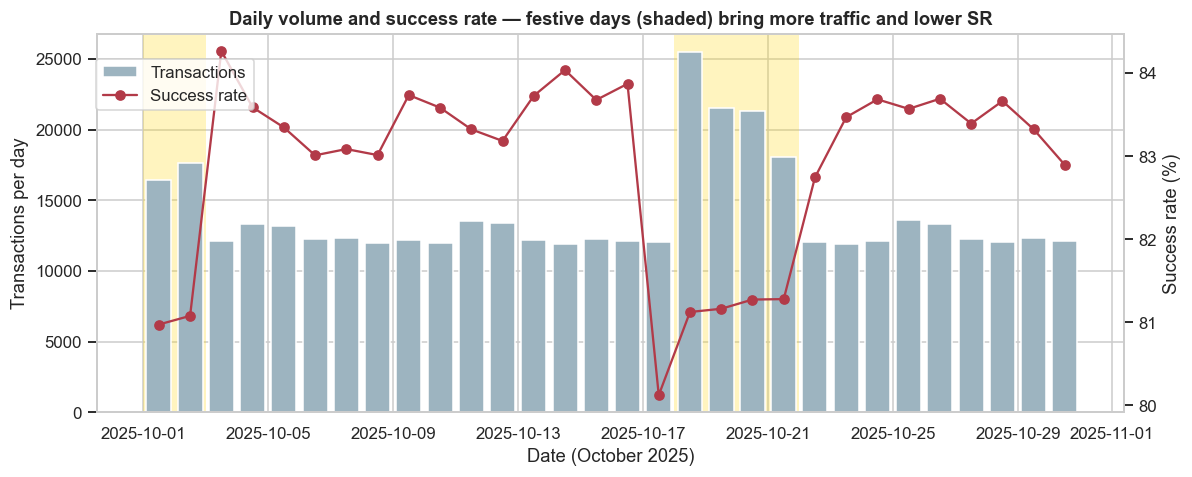

           avg_txns  avg_sr
festive                    
False   12,449.2083  0.8333
True    20,081.1667  0.8115


In [10]:
daily = clean.set_index("timestamp").resample("D").agg(txns=("success", "size"), sr=("success", "mean"))
fig, ax1 = plt.subplots(figsize=(11, 4.5))
festive_days = pd.to_datetime(list(gen.FESTIVE))
for d in festive_days:
    ax1.axvspan(d, d + pd.Timedelta(days=1), color="gold", alpha=0.25, lw=0)
ax1.bar(daily.index + pd.Timedelta(hours=12), daily.txns, width=0.8, color="#9db4c0", label="Transactions")
ax1.set_ylabel("Transactions per day"); ax1.set_xlabel("Date (October 2025)")
ax2 = ax1.twinx(); ax2.plot(daily.index + pd.Timedelta(hours=12), daily.sr * 100, color="#b23a48", marker="o", label="Success rate")
ax2.set_ylabel("Success rate (%)"); ax2.grid(False)
ax1.set_title("Daily volume and success rate — festive days (shaded) bring more traffic and lower SR")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88)); plt.tight_layout(); plt.show()
print(daily.assign(festive=daily.index.isin(festive_days)).groupby("festive").agg(avg_txns=("txns", "mean"), avg_sr=("sr", "mean")))

**Takeaway:** festive days (shaded) bring about **1.6× the normal daily volume** (≈ 20,100 vs 12,400 payments) *and* an SR about **2 pp lower** (81.2% vs 83.3%). The peak sale days are exactly when issuer banks are under strain, so this is when routing quality matters most. Each failed payment on a Diwali sale day is also a higher-intent customer.

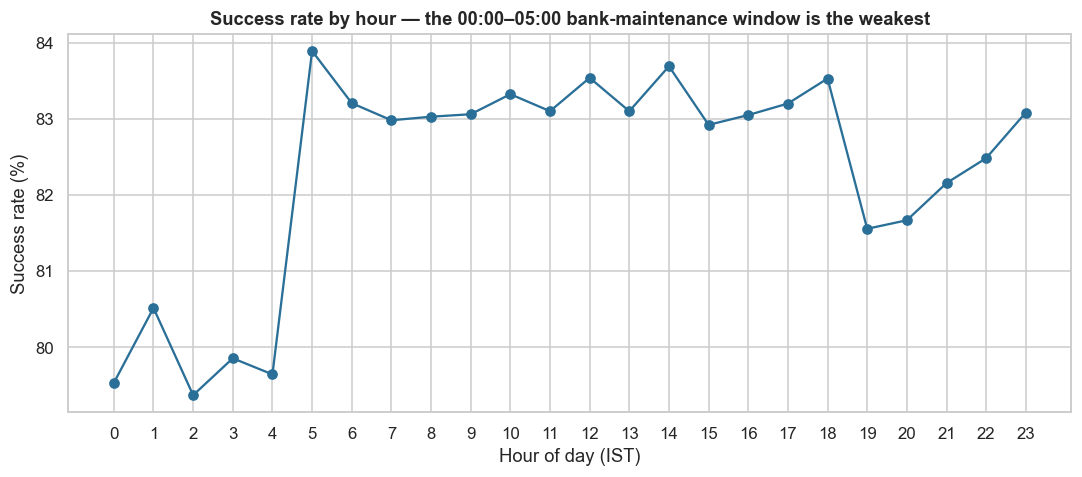

SR 00–05h: 79.78% | SR 05–24h: 82.85%


In [11]:
hourly = clean.groupby(clean.timestamp.dt.hour).agg(sr=("success", "mean"), txns=("success", "size"))
fig, ax = plt.subplots()
ax.plot(hourly.index, hourly.sr * 100, marker="o", color="#2a6f97")
ax.set_xticks(range(0, 24)); ax.set_xlabel("Hour of day (IST)"); ax.set_ylabel("Success rate (%)")
ax.set_title("Success rate by hour — the 00:00–05:00 bank-maintenance window is the weakest")
plt.tight_layout(); plt.show()
print(f"SR 00–05h: {clean[clean.timestamp.dt.hour < 5].success.mean():.2%} | SR 05–24h: {clean[clean.timestamp.dt.hour >= 5].success.mean():.2%}")

**Takeaway:** SR drops by about 3 pp between midnight and 5 am (79.8% vs 82.8% for the rest of the day), when banks run batch and maintenance jobs. Any monitoring alert must allow for this daily pattern, or it will fire every night (see Section 7.7).

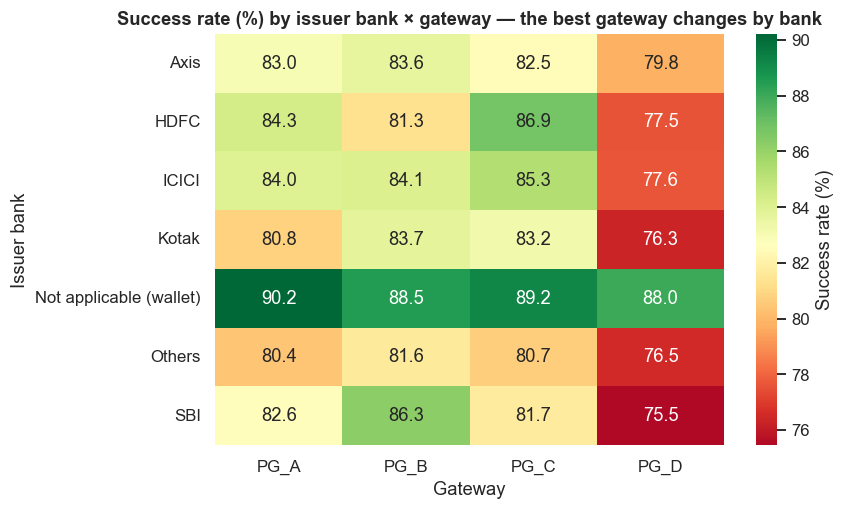

In [12]:
seg = clean.groupby(["issuer_bank", "gateway"]).success.mean().unstack() * 100
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(seg, annot=True, fmt=".1f", cmap="RdYlGn", center=seg.values.mean(), cbar_kws={"label": "Success rate (%)"}, ax=ax)
ax.set_title("Success rate (%) by issuer bank × gateway — the best gateway changes by bank")
ax.set_xlabel("Gateway"); ax.set_ylabel("Issuer bank")
plt.tight_layout(); plt.show()

**Takeaway:** no single column is green everywhere. **PG_B leads for SBI, Kotak, Axis and smaller banks; PG_C leads for HDFC and ICICI; PG_A leads for wallets.** The SBI gap between PG_B and PG_A is about 3 pp. A fixed "send everything to gateway X" rule leaves money on the table for every bank where X is not the best.

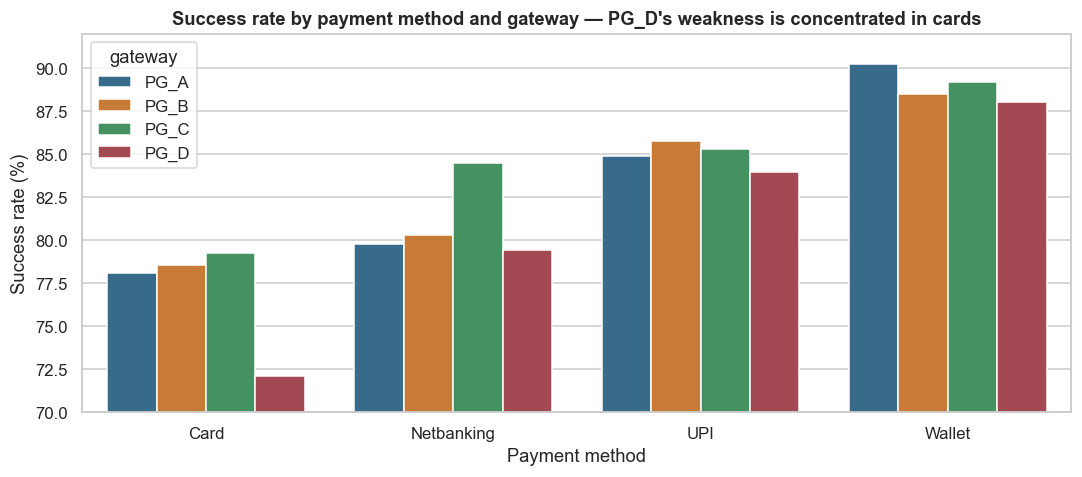

Traffic mix by gateway (% of each gateway's traffic):
payment_method    Card  Netbanking     UPI  Wallet
gateway                                           
PG_A           23.7000      7.2000 62.3000  6.9000
PG_B           23.1000      6.7000 63.2000  6.9000
PG_C           23.2000     22.4000 46.6000  7.7000
PG_D           51.1000      9.1000 33.4000  6.5000
Card SR by gateway (%): {'PG_A': 78.11, 'PG_B': 78.56, 'PG_C': 79.23, 'PG_D': 72.11}


In [13]:
m = clean.groupby(["payment_method", "gateway"]).success.mean().mul(100).reset_index()
fig, ax = plt.subplots()
sns.barplot(data=m, x="payment_method", y="success", hue="gateway", palette=PALETTE, ax=ax)
ax.set_ylim(70, 92); ax.set_xlabel("Payment method"); ax.set_ylabel("Success rate (%)")
ax.set_title("Success rate by payment method and gateway — PG_D's weakness is concentrated in cards")
plt.tight_layout(); plt.show()
mix = pd.crosstab(clean.gateway, clean.payment_method, normalize="index").mul(100).round(1)
print("Traffic mix by gateway (% of each gateway's traffic):"); print(mix)
print("Card SR by gateway (%):", (clean[clean.payment_method == "Card"].groupby("gateway").success.mean() * 100).round(2).to_dict())

**Takeaway:** PG_D loses about **6–7 pp** to the others on **cards** (72.1% vs 78–79%), but is within about 1–2 pp on UPI and wallets. PG_C is the clear Netbanking specialist (84.5% vs ≈ 80%). The traffic-mix table also shows that **PG_D gets about 2× more card traffic than the others** (51% of its traffic vs ≈ 23%, because of the cost rule), and cards are the hardest method. Part of PG_D's poor *overall* number is therefore the *mix* of traffic it is given, not the gateway itself. We adjust for this in Section 7.2.

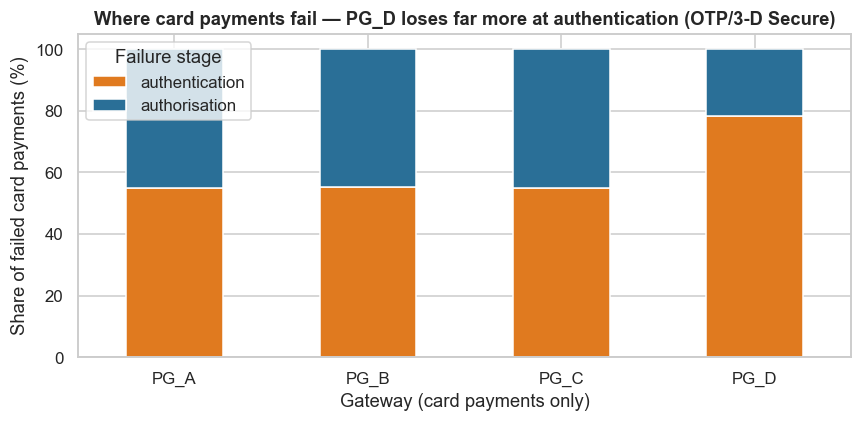

         authentication failure rate %  authorisation failure rate %
gateway                                                             
PG_A                           12.0200                        9.8700
PG_B                           11.8500                        9.5900
PG_C                           11.4200                        9.3500
PG_D                           21.8000                        6.0900


In [14]:
fails = clean[clean.success == 0]
stage = pd.crosstab([fails.payment_method, fails.gateway], fails.failure_stage, normalize="index").mul(100)
card_stage = stage.loc["Card"]
ax = card_stage[["authentication", "authorisation"]].plot(kind="bar", stacked=True, color=["#e07a1f", "#2a6f97"], figsize=(8, 4))
ax.set_xlabel("Gateway (card payments only)"); ax.set_ylabel("Share of failed card payments (%)")
ax.set_title("Where card payments fail — PG_D loses far more at authentication (OTP/3-D Secure)")
ax.legend(title="Failure stage"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
card_fail_rate = clean[clean.payment_method == "Card"].assign(auth_fail=lambda d: d.failure_stage.eq("authentication"),
                                                              authz_fail=lambda d: d.failure_stage.eq("authorisation"))
print((card_fail_rate.groupby("gateway")[["auth_fail", "authz_fail"]].mean() * 100).round(2).rename(columns={
    "auth_fail": "authentication failure rate %", "authz_fail": "authorisation failure rate %"}))

**Takeaway:** this mirrors Cashfree's finding (Case Study 2). On cards, **PG_D's extra failures come entirely from the authentication step** (21.8% of card attempts fail at OTP/3-D Secure vs ≈ 12% elsewhere), while its authorisation (issuer-decline) rate is no worse (6.1% vs ≈ 9.6%; fewer payments survive to that stage). The operational fix may be to *split the flow*: authenticate on a stronger gateway and authorise on the cheap one. Routing alone cannot do that.

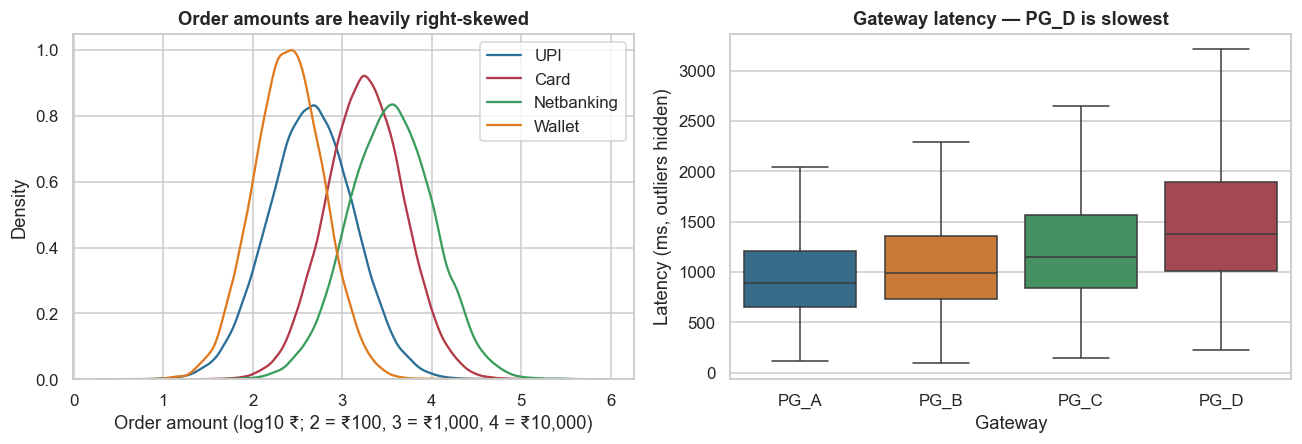

               50%        95%
gateway                      
PG_A      886.0000 1,897.0000
PG_B      994.0000 2,155.0000
PG_C    1,147.0000 2,459.0000
PG_D    1,382.0000 2,951.0000


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for mth, c in zip(["UPI", "Card", "Netbanking", "Wallet"], ["#2a6f97", "#b23a48", "#3a9d5d", "#e07a1f"]):
    sns.kdeplot(np.log10(clean.loc[clean.payment_method == mth, "amount_inr"]), ax=axes[0], label=mth, color=c, fill=False)
axes[0].set_xlabel("Order amount (log10 ₹; 2 = ₹100, 3 = ₹1,000, 4 = ₹10,000)"); axes[0].set_ylabel("Density")
axes[0].set_title("Order amounts are heavily right-skewed"); axes[0].legend()
sns.boxplot(data=clean.dropna(subset=["latency_ms"]), x="gateway", y="latency_ms", hue="gateway", palette=PALETTE,
            order=GATEWAYS, showfliers=False, legend=False, ax=axes[1])
axes[1].set_xlabel("Gateway"); axes[1].set_ylabel("Latency (ms, outliers hidden)"); axes[1].set_title("Gateway latency — PG_D is slowest")
plt.tight_layout(); plt.show()
print(clean.groupby("gateway").latency_ms.describe(percentiles=[.5, .95])[["50%", "95%"]].round(0))

**Takeaway (left):** order values are log-normal. The median is about ₹760, but the mean is pulled up by large netbanking and card orders. When we put a ₹ value on recovered payments, we must use the *actual amounts* of the recovered payments, not an average guess. **Takeaway (right):** PG_D is also the slowest gateway (median ≈ 1.38 s vs ≈ 0.89 s for PG_A; p95 ≈ 2.95 s), so latency is a sensible guardrail: a router that chases SR must not push customers onto a much slower gateway.

## 7. Statistical Analysis (core section)

Every test below follows the same template: **(a) why this test, (b) assumption checks, (c) result with effect size and CI, (d) power/MDE, (e) multiple-testing control where relevant, (f) what it means for the business.**

Two terms used throughout:
- A **p-value** is the probability of seeing a difference at least this large *if there were really no difference*. Small p-values (< 0.05) mean "unlikely to be pure chance".
- A **confidence interval (CI)** is the range of plausible values for the true number. A 95% CI is built so that, over many repeats, 95% of such ranges contain the truth.

### 7.1 Success rate per gateway with Wilson 95% confidence intervals

**(a) Why Wilson?** SR is a **binomial proportion** (each payment either succeeds or fails), which is the model the Juspay paper documents. The textbook "Wald" interval (p ± 1.96·SE) behaves badly near 0 or 1 and for small windows. The **Wilson score interval** keeps the right coverage at any sample size, so we use it everywhere, including the small 15-minute windows later (D-1-09).
**(b) Assumptions:** independent attempts (after de-duplication), constant SR within the group. Both hold approximately; customer retries create mild dependence (see Limitations).

In [16]:
def wilson_table(d, by):
    g = d.groupby(by).success.agg(successes="sum", n="size")
    g["SR"] = g.successes / g.n
    lo, hi = proportion_confint(g.successes, g.n, alpha=0.05, method="wilson")
    g["CI_low"], g["CI_high"] = lo, hi
    g["CI_width_pp"] = (hi - lo) * 100
    return g

gw_tab = wilson_table(clean, "gateway").sort_values("SR", ascending=False)
gw_tab

,successes,n,SR,CI_low,CI_high,CI_width_pp
gateway,,,,,,
PG_C,62708,74656,0.8400,0.8373,0.8426,0.5260
PG_B,106637,127067,0.8392,0.8372,0.8412,0.4039
PG_A,123942,148772,0.8331,0.8312,0.8350,0.3790
PG_D,53484,68773,0.7777,0.7746,0.7808,0.6215


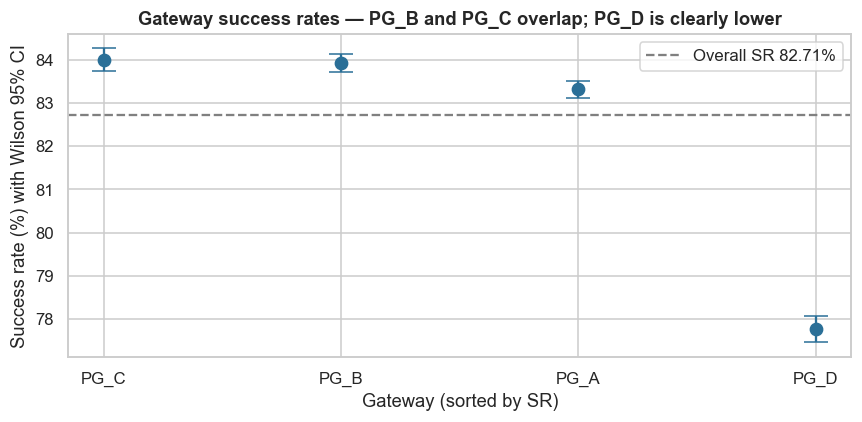

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(gw_tab.index, gw_tab.SR * 100, yerr=[(gw_tab.SR - gw_tab.CI_low) * 100, (gw_tab.CI_high - gw_tab.SR) * 100],
            fmt="o", capsize=8, color="#2a6f97", ms=8)
ax.axhline(clean.success.mean() * 100, ls="--", color="grey", label=f"Overall SR {clean.success.mean():.2%}")
ax.set_xlabel("Gateway (sorted by SR)"); ax.set_ylabel("Success rate (%) with Wilson 95% CI")
ax.set_title("Gateway success rates — PG_B and PG_C overlap; PG_D is clearly lower"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** with roughly 70,000–150,000 payments per gateway, each CI is only about ±0.2–0.3 pp wide. The PG_C (84.00%) and PG_B (83.92%) intervals overlap almost completely, PG_A is about 0.6 pp behind them, and PG_D (77.8%) sits clearly below everyone. At this scale, a gap smaller than about half a point needs a formal test, not eyeballing.

### 7.2 Two-proportion Z-test: best vs second-best gateway, with Cohen's h

**(a) Why a Z-test?** We compare two independent proportions with very large samples. The two-proportion Z-test is the documented Juspay method. It is mathematically the same as a 2×2 chi-square test (Z² = χ²), but it also gives a *direction* and a CI for the difference, which managers need ("B beats C by x pp"). See D-1-11.
**Effect size — Cohen's h:** h = 2·arcsin√p₁ − 2·arcsin√p₂. It is a scale-free size of the difference between two proportions. Rules of thumb: 0.2 = small, 0.5 = medium, 0.8 = large. With millions of payments a tiny h can still be "significant", so h tells us whether the gap *matters*.
**(b) Assumptions:** n·p and n·(1−p) ≥ 10 in both groups (normal approximation); independent groups (each payment goes to exactly one gateway); no confounding (we check this with Mantel–Haenszel next).

In [18]:
best, second = gw_tab.index[0], gw_tab.index[1]
s = gw_tab.loc[[best, second]]
print("Assumption check - min of n*p and n*(1-p):", int(min((s.n * s.SR).min(), (s.n * (1 - s.SR)).min())), "(needs >= 10)")
z, p = proportions_ztest(s.successes.values, s.n.values, alternative="two-sided")
h = proportion_effectsize(s.SR.iloc[0], s.SR.iloc[1])
ci_lo, ci_hi = confint_proportions_2indep(s.successes.iloc[0], s.n.iloc[0], s.successes.iloc[1], s.n.iloc[1], method="newcomb")
diff = s.SR.iloc[0] - s.SR.iloc[1]
print(f"{best} vs {second}: diff = {diff*100:+.3f} pp, 95% CI [{ci_lo*100:+.3f}, {ci_hi*100:+.3f}] pp")
print(f"Z = {z:.3f}, p-value = {p:.4f}, Cohen's h = {h:.4f}")
# power we had for a 0.5 pp gap at these sample sizes
h05 = proportion_effectsize(s.SR.iloc[1] + 0.005, s.SR.iloc[1])
pw = NormalIndPower().power(effect_size=h05, nobs1=s.n.iloc[0], ratio=s.n.iloc[1] / s.n.iloc[0], alpha=0.05)
print(f"Power to detect a 0.5 pp gap with these sample sizes: {pw:.1%}")

Assumption check - min of n*p and n*(1-p): 11948 (needs >= 10)
PG_C vs PG_B: diff = +0.074 pp, 95% CI [-0.258, +0.405] pp
Z = 0.438, p-value = 0.6617, Cohen's h = 0.0020
Power to detect a 0.5 pp gap with these sample sizes: 84.4%


In [19]:
# Also every pair (for completeness), Holm-corrected
pairs = []
for i, a in enumerate(GATEWAYS):
    for b in GATEWAYS[i + 1:]:
        ra, rb = gw_tab.loc[a], gw_tab.loc[b]
        zz, pp = proportions_ztest([ra.successes, rb.successes], [ra.n, rb.n])
        pairs.append((f"{a} vs {b}", (ra.SR - rb.SR) * 100, zz, pp, proportion_effectsize(ra.SR, rb.SR)))
pairs = pd.DataFrame(pairs, columns=["pair", "diff_pp", "Z", "p_raw", "cohens_h"])
pairs["p_holm"] = multipletests(pairs.p_raw, method="holm")[1]
pairs["significant (Holm, 5%)"] = pairs.p_holm < 0.05
pairs

,pair,diff_pp,Z,p_raw,cohens_h,p_holm,"significant (Holm, 5%)"
0,PG_A vs PG_B,-0.6118,-4.3249,0.0000,-0.0165,0.0000,True
1,PG_A vs PG_C,-0.6859,-4.1239,0.0000,-0.0185,0.0001,True
2,PG_A vs PG_D,5.5411,30.9856,0.0000,0.1403,0.0000,True
3,PG_B vs PG_C,-0.0741,-0.4375,0.6617,-0.0020,0.6617,False
4,PG_B vs PG_D,6.1530,33.6579,0.0000,0.1568,0.0000,True
5,PG_C vs PG_D,6.2270,30.0382,0.0000,0.1588,0.0000,True


**Confounding check: Mantel–Haenszel (MH) test stratified by payment method.** Today's rules send different method mixes to different gateways (Section 6), so a raw comparison may partly compare *traffic mixes* instead of gateways. This is the classic route to **Simpson's paradox**, where an overall comparison points the opposite way from every sub-group. The **Mantel–Haenszel** test combines the 2×2 comparison *within* each payment method into one pooled odds ratio, which removes the mix effect. We also run a logistic regression that adjusts for method, bank, hour and festive day, and repeat the comparison without the outage window.

In [20]:
def mh_compare(d, a, b, strata="payment_method"):
    tables = []
    for _, g in d[d.gateway.isin([a, b])].groupby(strata):
        t = pd.crosstab(g.gateway, g.success).reindex(index=[a, b], columns=[1, 0]).fillna(0).values
        if (t.sum(axis=1) > 0).all():
            tables.append(t)
    st = StratifiedTable(tables)
    res = st.test_null_odds(correction=False)
    return st.oddsratio_pooled, st.oddsratio_pooled_confint(), res.pvalue, st.test_equal_odds().pvalue

or_, (or_lo, or_hi), p_mh, p_bd = mh_compare(clean, best, second)
print(f"MH pooled odds ratio {best} vs {second} (within payment method): {or_:.4f}  95% CI [{or_lo:.4f}, {or_hi:.4f}], p = {p_mh:.4f}")
print(f"Breslow-Day test of equal odds ratios across methods: p = {p_bd:.4f}  (small p = the gap differs by method)")

no_outage = clean[~((clean.gateway == gen.OUTAGE["gateway"]) & clean.timestamp.between(gen.OUTAGE["start"], gen.OUTAGE["end"], inclusive="left"))]
t2 = wilson_table(no_outage, "gateway").sort_values("SR", ascending=False)
print("\nSR excluding the 2.5-hour PG_B outage window:"); print(t2[["SR", "CI_low", "CI_high", "n"]])

clean["hour"] = clean.timestamp.dt.hour
clean["night"] = clean.hour.between(0, 4).astype(int)
clean["festive"] = clean.timestamp.dt.strftime("%Y-%m-%d").isin(list(gen.FESTIVE)).astype(int)
adj = smf.logit("success ~ C(gateway, Treatment('PG_C')) + C(payment_method) + C(issuer_bank) + night + festive", data=clean).fit(disp=0)
coef = adj.summary2().tables[1].filter(like="gateway", axis=0)
coef["odds_ratio_vs_PG_C"] = np.exp(coef["Coef."])
print("\nAdjusted logistic regression (reference = PG_C):"); print(coef[["Coef.", "P>|z|", "odds_ratio_vs_PG_C"]].round(4))

MH pooled odds ratio PG_C vs PG_B (within payment method): 1.0364  95% CI [1.0104, 1.0630], p = 0.0055
Breslow-Day test of equal odds ratios across methods: p = 0.0000  (small p = the gap differs by method)

SR excluding the 2.5-hour PG_B outage window:
            SR  CI_low  CI_high       n
gateway                                
PG_B    0.8422  0.8401   0.8442  126382
PG_C    0.8400  0.8373   0.8426   74656
PG_A    0.8331  0.8312   0.8350  148772
PG_D    0.7777  0.7746   0.7808   68773



Adjusted logistic regression (reference = PG_C):
                                        Coef.  P>|z|  odds_ratio_vs_PG_C
C(gateway, Treatment('PG_C'))[T.PG_A] -0.0845 0.0000              0.9190
C(gateway, Treatment('PG_C'))[T.PG_B] -0.0435 0.0007              0.9574
C(gateway, Treatment('PG_C'))[T.PG_D] -0.2904 0.0000              0.7480


**(c) Result, (d) power, (f) what this means for the business:**

- **Result.** The two best gateways, **PG_C (84.00%) and PG_B (83.92%), differ by only +0.07 pp** (95% CI −0.26 to +0.41 pp; Z = 0.44, p = 0.66; Cohen's h = 0.002, negligible). **We cannot reject H0: neither is "the best gateway" overall.**
- **Power.** With these sample sizes we had **84% power to detect a 0.5 pp gap**, so this is an *informative* null. If one of them were 0.5 pp or more better overall, we would very likely have seen it.
- **Other pairs** (Holm-corrected): PG_B and PG_C beat PG_A by about 0.6–0.7 pp, and everyone beats PG_D by 5.5–6.2 pp (h ≈ 0.14–0.16, "small" on Cohen's yardstick but large in money).
- **The overall number hides the real story.** (1) *Mantel–Haenszel* within payment method: OR = 1.036 [1.010, 1.063], p = 0.006. Once we compare like with like, PG_C is slightly better, because PG_C carries more of the harder Netbanking traffic. (2) *Breslow–Day* p < 0.001: the PG_C-vs-PG_B gap **differs by payment method**, so no single pooled number describes it. (3) *Excluding the outage*, PG_B tops the table (84.22%). (4) The *adjusted logistic regression* puts PG_D's odds of success **25% below PG_C's (OR 0.75)** even after controlling for method, bank, night and festive days, so PG_D's weakness is real, not just its traffic mix.

**What this means for the business:** there is no single gateway we can safely send everything to. PG_D is genuinely weaker, mostly on cards. Between PG_B and PG_C, the winner flips depending on how we slice the data (by method, with or without the outage). That is the statistical signature of a *segment-specific* problem, which is exactly what dynamic routing is built for.

### 7.3 Chi-square tests of independence, with Cramér's V

**(a) Why chi-square?** These questions involve *more than two* categories (4 payment methods, 4 gateways, 7 bank groups). The chi-square test of independence asks: "if outcome had nothing to do with the category, how surprising would these counts be?" (D-1-12).
**Effect size — Cramér's V:** this rescales chi-square to run from 0 (no association) to 1 (perfect association), so we can judge *strength*. As a rule of thumb, for a 2-column table 0.1 is small, 0.3 medium and 0.5 large.
**(b) Assumptions:** independent observations, and **expected count ≥ 5 in every cell** (otherwise the chi-square approximation breaks down). We print the minimum expected count for each test.

In [21]:
def chi_square_report(d, row, col="success", label=None):
    tab = pd.crosstab(d[row], d[col])
    chi2, p, dof, exp = stats.chi2_contingency(tab, correction=False)
    n = tab.values.sum(); k = min(tab.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    return {"test": label or f"{row} × {col}", "chi2": chi2, "dof": dof, "p_value": p, "cramers_V": v,
            "min_expected": exp.min(), "cells_expected<5": int((exp < 5).sum()), "n": n}

chi_main = pd.DataFrame([chi_square_report(clean, "payment_method", label="payment_method × outcome"),
                         chi_square_report(clean, "gateway", label="gateway × outcome"),
                         chi_square_report(clean, "issuer_bank", label="issuer_bank × outcome")])
chi_main

,test,chi2,dof,p_value,cramers_V,min_expected,cells_expected<5,n
0,payment_method × outcome,"4,937.5064",3,0.0000,0.1085,"5,062.3817",0,419268
1,gateway × outcome,"1,428.3122",3,0.0000,0.0584,"11,891.7642",0,419268
2,issuer_bank × outcome,"1,173.3167",6,0.0000,0.0529,"5,062.3817",0,419268


**Gateway × issuer bank × outcome (three-way).** We approach the three-way question in two complementary ways:
1. **Stratified chi-square:** within each bank, is outcome independent of gateway? We run 7 tests, so we apply the Holm correction.
2. **Formal interaction test:** a logistic regression with and without the `gateway × bank` interaction, compared with a **likelihood-ratio (LR) test**. A significant LR test means "the best gateway depends on the bank".

In [22]:
by_bank = pd.DataFrame([chi_square_report(g, "gateway", label=b) for b, g in clean.groupby("issuer_bank")])
by_bank["p_holm"] = multipletests(by_bank.p_value, method="holm")[1]
best_by_bank = clean.groupby(["issuer_bank", "gateway"]).success.mean().unstack().idxmax(axis=1)
by_bank["best_gateway"] = by_bank.test.map(best_by_bank)
by_bank.rename(columns={"test": "issuer_bank"})[["issuer_bank", "chi2", "dof", "p_value", "p_holm", "cramers_V", "min_expected", "best_gateway"]]

,issuer_bank,chi2,dof,p_value,p_holm,cramers_V,min_expected,best_gateway
0,Axis,54.6048,3,0.0000,0.0000,0.0341,"1,327.6204",PG_B
1,HDFC,541.0031,3,0.0000,0.0000,0.0791,"2,483.7004",PG_C
2,ICICI,317.5104,3,0.0000,0.0000,0.0672,"1,944.3656",PG_C
3,Kotak,134.9374,3,0.0000,0.0000,0.0659,960.4581,PG_B
4,Not applicable (wallet),21.9221,3,0.0001,0.0001,0.0274,483.9303,PG_A
5,Others,107.8122,3,0.0000,0.0000,0.0430,"1,913.6275",PG_B
6,SBI,844.2084,3,0.0000,0.0000,0.0933,"2,802.7225",PG_B


In [23]:
m_add = smf.logit("success ~ C(gateway) + C(issuer_bank) + C(payment_method)", data=clean).fit(disp=0)
m_int = smf.logit("success ~ C(gateway) * C(issuer_bank) + C(payment_method)", data=clean).fit(disp=0)
lr = 2 * (m_int.llf - m_add.llf); df_lr = m_int.df_model - m_add.df_model
p_lr = stats.chi2.sf(lr, df_lr)
print(f"Likelihood-ratio test, gateway x bank interaction: LR = {lr:.1f}, df = {df_lr:.0f}, p = {p_lr:.3g}")
print(f"AIC additive = {m_add.aic:,.0f} | AIC with interaction = {m_int.aic:,.0f}  (lower is better)")

Likelihood-ratio test, gateway x bank interaction: LR = 609.6, df = 18, p = 7.87e-118
AIC additive = 380,521 | AIC with interaction = 379,947  (lower is better)


In [24]:
# Failure stage x gateway, among failed CARD payments (Cashfree-style funnel decomposition)
card_fails = clean[(clean.payment_method == "Card") & (clean.success == 0)]
r = chi_square_report(card_fails, "gateway", col="failure_stage", label="gateway × failure_stage (failed cards)")
pd.DataFrame([r])

,test,chi2,dof,p_value,cramers_V,min_expected,cells_expected<5,n
0,gateway × failure_stage (failed cards),"1,449.3579",3,0.0000,0.2300,"1,320.3688",0,27402


**(f) What this means for the business:**

- Every association is statistically certain (all p < 10⁻⁵⁰), and every table passes the expected-count check comfortably (smallest expected cell ≈ 484, far above 5).
- **But the effect sizes are small:** Cramér's V = 0.11 for payment method, 0.06 for gateway, 0.05 for bank. Payment method is the strongest single driver of success. With 4 lakh payments, "significant" is easy. Cramér's V tells us these are modest per-payment effects, which matter because they repeat lakhs of times a month.
- **Within each bank**, gateway choice matters in all 7 groups (all survive Holm). It matters most for SBI (V = 0.09) and HDFC (V = 0.08).
- **The gateway × bank interaction is overwhelming:** LR = 610 on 18 df, p ≈ 10⁻¹¹⁸, and AIC improves by 574 points. **The best gateway genuinely depends on the customer's bank:** PG_B for SBI, Kotak, Axis and smaller banks; PG_C for HDFC and ICICI; PG_A for wallets.
- **Failure stage × gateway (failed cards)** has the largest effect size in this section (V = 0.23): PG_D's card failures are disproportionately at authentication.

**What this means for the business:** the interaction test is the formal proof that *one fixed rule cannot be optimal for everyone*. The authentication finding points to a specific, non-ML fix: raise PG_D's 3-D Secure / OTP performance with them commercially, or split the card flow (authenticate elsewhere, authorise on the cheaper PG_D), as Cashfree did for a documented 2% SR gain.

### 7.4 Sample size and minimum detectable effect (MDE)

**Business question:** *"If we A/B test a routing change, how many payments do we need before we can trust the answer?"*

**Power** is the probability that a test detects a real difference of a given size; 80% is the industry convention. The **MDE** is the smallest true difference a test can reliably detect (at that power) with a given sample. Here we want to detect a **0.5 pp** SR difference from a baseline of about 82.7% at α = 0.05, two-sided, with 80% power (D-1-10).

Formula (per arm, equal split): n = 2·(z₁₋α/₂ + z₁₋β)² / h², where h is Cohen's h for 82.7% vs 83.2%. The 2 appears because both arms' estimates are noisy (variance of the arcsine-transformed difference = 2/n). We cross-check with the classic formula on the proportion scale.

In [25]:
p0 = clean.success.mean(); p1 = p0 + 0.005
h_mde = proportion_effectsize(p1, p0)
n_per_arm = NormalIndPower().solve_power(effect_size=h_mde, alpha=0.05, power=0.80, ratio=1.0, alternative="two-sided")
n_manual = 2 * (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) ** 2 / h_mde ** 2          # two-sample: Var(h_hat) = 2/n
pbar = (p0 + p1) / 2
n_classic = (stats.norm.ppf(0.975) * np.sqrt(2 * pbar * (1 - pbar)) + stats.norm.ppf(0.80) * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p1 - p0) ** 2
daily_vol = len(clean) / 30
print(f"Baseline SR = {p0:.4f}; target = {p1:.4f}; Cohen's h = {h_mde:.5f}")
print(f"Required n per arm = {n_per_arm:,.0f} (arcsine formula: {n_manual:,.0f}; classic proportions formula: {n_classic:,.0f}); total = {2*n_per_arm:,.0f}")
print(f"At {daily_vol:,.0f} payments/day split 50/50 -> {2*n_per_arm/daily_vol:.1f} days of traffic (round up to whole weeks: 14 days)")
# MDE achievable with different sample sizes
ns = np.array([5_000, 10_000, 25_000, 50_000, 100_000, 200_000, 500_000])
mde_rows = []
for n in ns:
    h_ = NormalIndPower().solve_power(nobs1=n, alpha=0.05, power=0.80, ratio=1.0)
    p_det = np.sin(np.arcsin(np.sqrt(p0)) + h_ / 2) ** 2
    mde_rows.append((n, (p_det - p0) * 100))
mde = pd.DataFrame(mde_rows, columns=["n_per_arm", "MDE_pp"])
mde

Baseline SR = 0.8271; target = 0.8321; Cohen's h = 0.01330
Required n per arm = 88,765 (arcsine formula: 88,765; classic proportions formula: 88,768); total = 177,530
At 13,976 payments/day split 50/50 -> 12.7 days of traffic (round up to whole weeks: 14 days)


,n_per_arm,MDE_pp
0,5000,2.0665
1,10000,1.4724
2,25000,0.9373
3,50000,0.6649
4,100000,0.4712
5,200000,0.3337
6,500000,0.2114


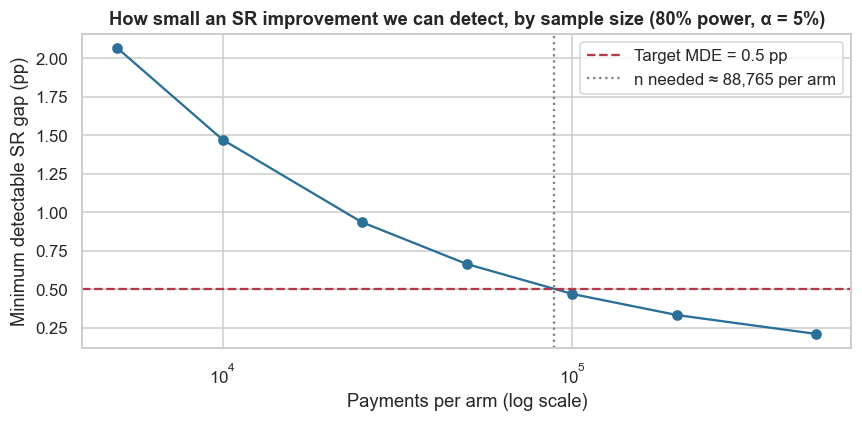

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mde.n_per_arm, mde.MDE_pp, marker="o", color="#2a6f97")
ax.axhline(0.5, ls="--", color="#b23a48", label="Target MDE = 0.5 pp")
ax.axvline(n_per_arm, ls=":", color="grey", label=f"n needed ≈ {n_per_arm:,.0f} per arm")
ax.set_xscale("log"); ax.set_xlabel("Payments per arm (log scale)"); ax.set_ylabel("Minimum detectable SR gap (pp)")
ax.set_title("How small an SR improvement we can detect, by sample size (80% power, α = 5%)"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** to detect a 0.5 pp improvement reliably we need about **88,800 payments per arm** (≈ 1.78 lakh in total). That is roughly **13 days** of this merchant group's traffic with a 50/50 split. Both formulas agree. We recommend running for **two full weeks**, so every weekday and weekend pattern is covered. A 10,000-payment pilot could only detect gaps of about 1.5 pp, which is too coarse for routing decisions where the documented gains are 0.6–1.2 pp. A sanity check against the paper: Juspay's worked example uses about 1,104 transactions in a 2-hour window. At that size only gaps of roughly 4–6 pp are detectable, so such windows suit *outage* detection (large drops), not fine gateway ranking.

### 7.5 Segment-wise comparisons with Holm–Bonferroni correction

**Business view:** routing works per segment (e.g., "UPI from SBI customers"). If we test 19 segments at 5% each, we should expect about 1 false "winner" by pure luck, even if no gateway were better anywhere. That is the **multiple-testing problem**.
**Holm–Bonferroni** controls the **family-wise error rate (FWER)**, the chance of *even one* false winner, at 5%. It sorts the p-values and compares the smallest to α/m, the next to α/(m−1), and so on. It is uniformly more powerful than plain Bonferroni, and unlike the Benjamini–Hochberg (FDR) method it does not need assumptions about how the tests depend on each other (D-1-13). A false routing "winner" moves real money, so we want FWER rather than FDR control.

**Avoiding the winner's curse:** if we pick the best and second-best gateway *and* test them on the same data, the test is biased in favour of finding a difference. So we **pick on days 1–15 (discovery)** and **test on days 16–30 (confirmation)**.

In [27]:
clean["segment"] = clean.payment_method + " | " + clean.issuer_bank.str.replace("Not applicable (wallet)", "—", regex=False)
disc = clean[clean.timestamp < "2025-10-16"]; conf = clean[clean.timestamp >= "2025-10-16"]
rows = []
for sname, g in disc.groupby("segment"):
    ranking = g.groupby("gateway").success.mean().sort_values(ascending=False)
    b1, b2 = ranking.index[:2]
    c = conf[conf.segment == sname]
    x = c.groupby("gateway").success.agg(["sum", "size"])
    if not {b1, b2} <= set(x.index):
        continue
    zz, pp = proportions_ztest([x.loc[b1, "sum"], x.loc[b2, "sum"]], [x.loc[b1, "size"], x.loc[b2, "size"]])
    sr1, sr2 = x.loc[b1, "sum"] / x.loc[b1, "size"], x.loc[b2, "sum"] / x.loc[b2, "size"]
    rows.append((sname, b1, b2, x.loc[b1, "size"], x.loc[b2, "size"], (sr1 - sr2) * 100, proportion_effectsize(sr1, sr2), zz, pp))
segtests = pd.DataFrame(rows, columns=["segment", "best (disc.)", "2nd (disc.)", "n_best", "n_2nd", "diff_pp (conf.)", "cohens_h", "Z", "p_raw"])
segtests["p_holm"] = multipletests(segtests.p_raw, method="holm")[1]
segtests["p_bonferroni"] = multipletests(segtests.p_raw, method="bonferroni")[1]
segtests["sig_raw"] = segtests.p_raw < 0.05
segtests["sig_holm"] = segtests.p_holm < 0.05
print(f"{len(segtests)} segment tests | significant unadjusted: {segtests.sig_raw.sum()} | after Holm: {segtests.sig_holm.sum()} "
      f"| after Bonferroni: {(segtests.p_bonferroni < .05).sum()}")
segtests.sort_values("p_raw").round(4)

19 segment tests | significant unadjusted: 8 | after Holm: 4 | after Bonferroni: 4


,segment,best (disc.),2nd (disc.),n_best,n_2nd,diff_pp (conf.),cohens_h,Z,p_raw,p_holm,p_bonferroni,sig_raw,sig_holm
17,UPI | SBI,PG_B,PG_A,10588,12195,3.2112,0.0941,7.0462,0.0000,0.0000,0.0000,True,True
8,Netbanking | ICICI,PG_C,PG_A,1624,1066,7.3432,0.1950,5.0090,0.0000,0.0000,0.0000,True,True
5,Card | SBI,PG_B,PG_A,3873,4637,3.8693,0.0951,4.3517,0.0000,0.0002,0.0003,True,True
7,Netbanking | HDFC,PG_C,PG_A,2001,1342,5.1638,0.1430,4.0968,0.0000,0.0007,0.0008,True,True
1,Card | HDFC,PG_C,PG_A,2056,4075,3.0003,0.0774,2.8318,0.0046,0.0694,0.0880,True,False
13,UPI | HDFC,PG_C,PG_A,4176,10880,1.6346,0.0484,2.6285,0.0086,0.1201,0.1629,True,False
18,Wallet | —,PG_A,PG_C,5500,3080,1.4935,0.0474,2.1217,0.0339,0.4402,0.6433,True,False
10,Netbanking | Others,PG_C,PG_D,1367,478,4.4420,0.1100,2.1094,0.0349,0.4402,0.6633,True,False
2,Card | ICICI,PG_C,PG_B,1586,2867,2.5006,0.0606,1.9238,0.0544,0.5982,1.0000,False,False
6,Netbanking | Axis,PG_C,PG_D,1029,370,3.5217,0.0924,1.5514,0.1208,1.0000,1.0000,False,False


**(f) What this means for the business:**

- Of 19 segment tests, **8 look significant before correction, but only 4 survive Holm**: UPI-SBI (PG_B beats PG_A by 3.2 pp), Card-SBI (PG_B +3.9 pp), Netbanking-ICICI (PG_C +7.3 pp) and Netbanking-HDFC (PG_C +5.2 pp). Plain Bonferroni gives the same 4 here; Holm can never reject fewer.
- Four more "winners" (Card-HDFC, UPI-HDFC, Wallet, Netbanking-Others) are **plausible but unproven**. Their raw p-values were below 0.05, but with 19 tries that is what luck alone could produce.
- One discovery-period winner (Card-Axis: PG_B over PG_A) **reverses** in the confirmation period. That is the winner's curse in action, and the reason we never test a winner on the data that picked it.

**What this means for the business:** if we stay with fixed rules, I would hard-code only the 4 confirmed segment rules. The remaining gaps are real in our simulation but too small to *prove* one segment at a time with two weeks of data. That is exactly where a learning router earns its keep: it keeps measuring those gaps instead of freezing a guess into a rule.

### 7.6 A warning about "peeking" in continuous monitoring

**Business view:** routing dashboards update every minute, so it is tempting to look at an A/B test every day and stop as soon as p < 0.05. **Don't.** Each look is another chance for noise to cross the line. The simulation below runs 2,000 **A/A tests**, where both arms have *exactly* the same SR, so every "significant" result is a false alarm. We peek once a day for 30 days.

In [28]:
n_sims, looks, per_day = 2000, 30, 5000
p_true = clean.success.mean()
sim_rng = np.random.default_rng(SEED)
succ = sim_rng.binomial(per_day, p_true, size=(n_sims, looks, 2)).cumsum(axis=1)
n_cum = per_day * np.arange(1, looks + 1)[None, :]
pa, pb = succ[..., 0] / n_cum, succ[..., 1] / n_cum
pool = (succ[..., 0] + succ[..., 1]) / (2 * n_cum)
zstat = (pa - pb) / np.sqrt(pool * (1 - pool) * 2 / n_cum)
fpr_final = (np.abs(zstat[:, -1]) > 1.96).mean()
fpr_peek = (np.abs(zstat) > 1.96).any(axis=1).mean()
crit_peek = np.quantile(np.abs(zstat).max(axis=1), 0.95)
print(f"False-positive rate, single look at day 30 : {fpr_final:.1%}  (should be ~5%)")
print(f"False-positive rate, peeking daily, stop at first p<0.05: {fpr_peek:.1%}")
print(f"|Z| threshold needed to keep 5% error with 30 daily peeks (Pocock-style constant): {crit_peek:.2f}")

False-positive rate, single look at day 30 : 4.8%  (should be ~5%)
False-positive rate, peeking daily, stop at first p<0.05: 26.8%
|Z| threshold needed to keep 5% error with 30 daily peeks (Pocock-style constant): 2.74


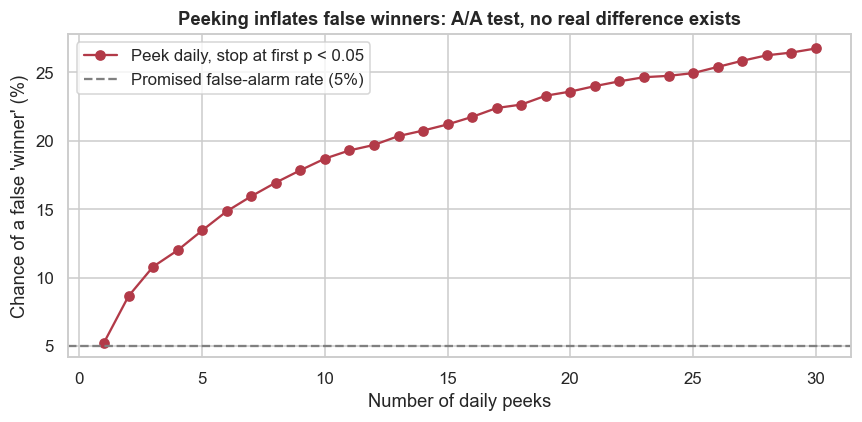

In [29]:
cum_fpr = [(np.abs(zstat[:, :k]) > 1.96).any(axis=1).mean() for k in range(1, looks + 1)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, looks + 1), np.array(cum_fpr) * 100, marker="o", color="#b23a48", label="Peek daily, stop at first p < 0.05")
ax.axhline(5, ls="--", color="grey", label="Promised false-alarm rate (5%)")
ax.set_xlabel("Number of daily peeks"); ax.set_ylabel("Chance of a false 'winner' (%)")
ax.set_title("Peeking inflates false winners: A/A test, no real difference exists"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** if we peek every day and stop at the first "significant" result, the chance of declaring a winner that does not exist rises from 5% (4.8% in the single-look simulation) to about **27%**, roughly one test in four. **I recommend:** (1) fix the sample size in advance (Section 7.4) and read the result once; or (2) if we must monitor continuously, use a **sequential design** with a stricter threshold. This simulation shows |Z| > 2.74 (instead of 1.96) keeps the 5% error over 30 daily looks; O'Brien–Fleming alpha-spending and always-valid p-values are refinements of the same idea. Note that **outage detection (next section) is a different job**: there we *want* fast alarms and accept some false ones, because the cost of an outage is much higher.

### 7.7 Outage detection: rolling SR and a p-chart (statistical process control)

**Business view:** Juspay detected downtime "within a minute". Our question: *can a simple statistical rule on SR alone catch the PG_B outage on 17 Oct quickly, without crying wolf every night?*

A **p-chart** is a control chart for proportions. For each 15-minute window it compares the gateway's SR to its normal level p̄. Lower control limit LCL = p̄ − 3·√(p̄(1−p̄)/nₜ), where nₜ is that window's volume. A point below the LCL is very unlikely under normal operation (about 0.13% chance per window if SR were truly constant). The limits widen automatically when volume is low (night) and tighten when it is high.

- **Phase I (baseline):** p̄ per gateway, estimated from days 1–7.
- **Rule 1:** one window below the LCL → alarm.
- **Rule 2 (Western-Electric style):** two consecutive windows below p̄ − 2σ → alarm. This is less trigger-happy at night.

In [30]:
win = (clean.groupby(["gateway", pd.Grouper(key="timestamp", freq="15min")]).success.agg(["sum", "size"])
            .rename(columns={"sum": "succ", "size": "n"}).reset_index())
win["sr"] = win.succ / win.n
base = clean[clean.timestamp < "2025-10-08"].groupby("gateway").success.mean().rename("pbar")
win = win.merge(base, on="gateway")
win["sigma"] = np.sqrt(win.pbar * (1 - win.pbar) / win.n)
win["LCL3"] = win.pbar - 3 * win.sigma
win["below3"] = win.sr < win.LCL3
win["below2"] = win.sr < win.pbar - 2 * win.sigma
win["rule2"] = win.groupby("gateway").below2.transform(lambda s: s & s.shift(1, fill_value=False))
o_start, o_end, o_gw = gen.OUTAGE["start"], gen.OUTAGE["end"], gen.OUTAGE["gateway"]
win["in_outage"] = (win.gateway == o_gw) & (win.timestamp >= o_start) & (win.timestamp < o_end)

summary = []
for rule in ["below3", "rule2"]:
    hits = win[(win.gateway == o_gw) & (win.timestamp >= o_start) & win[rule]]
    first = hits.timestamp.min()
    detect_at = first + pd.Timedelta(minutes=15)          # alarm fires when the window closes
    false_alarms = win[~win.in_outage & win[rule]]
    summary.append((rule, first, (detect_at - o_start).total_seconds() / 60, int(win.loc[win.in_outage, rule].sum()),
                    int(win.in_outage.sum()), len(false_alarms), len(false_alarms) / (~win.in_outage).sum()))
pd.DataFrame(summary, columns=["rule", "first flagged window", "minutes to alarm", "outage windows flagged",
                               "outage windows", "false alarms (30 days, 4 PGs)", "false-alarm rate per window"])

,rule,first flagged window,minutes to alarm,outage windows flagged,outage windows,"false alarms (30 days, 4 PGs)",false-alarm rate per window
0,below3,2025-10-17 19:00:00,15.0000,10,10,52,0.0045
1,rule2,2025-10-17 19:15:00,30.0000,9,10,18,0.0016


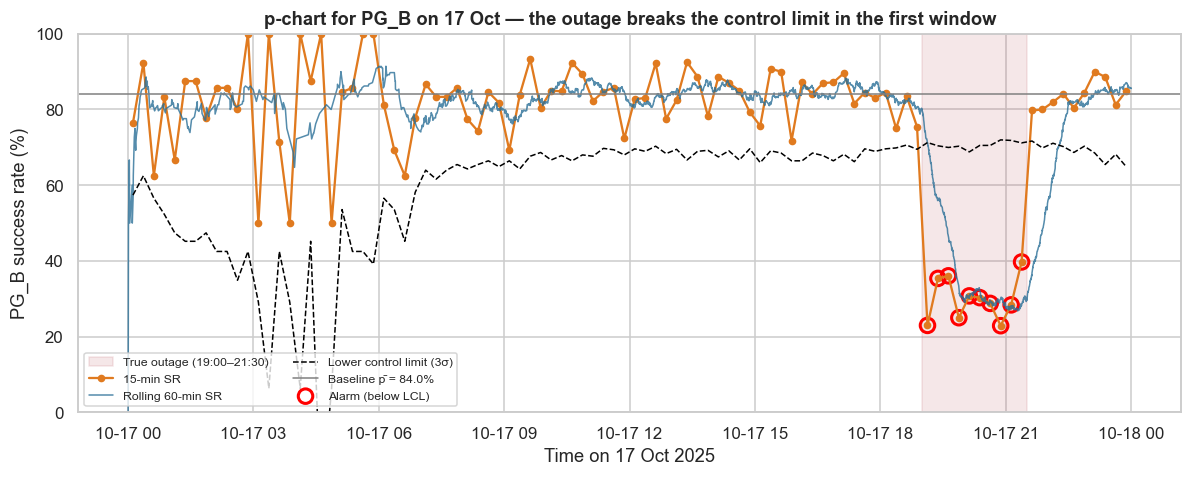

In [31]:
day = win[(win.gateway == o_gw) & (win.timestamp.dt.date == o_start.date())].copy()
roll = (clean[(clean.gateway == o_gw) & (clean.timestamp.dt.date == o_start.date())]
          .set_index("timestamp").success.rolling("60min").mean())
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axvspan(o_start, o_end, color="#b23a48", alpha=0.12, label="True outage (19:00–21:30)")
ax.plot(day.timestamp + pd.Timedelta(minutes=7.5), day.sr * 100, "o-", ms=4, color="#e07a1f", label="15-min SR")
ax.plot(roll.index, roll * 100, color="#2a6f97", lw=1, alpha=0.8, label="Rolling 60-min SR")
ax.plot(day.timestamp + pd.Timedelta(minutes=7.5), day.LCL3 * 100, "--", color="black", lw=1, label="Lower control limit (3σ)")
ax.axhline(day.pbar.iloc[0] * 100, color="grey", lw=1, label=f"Baseline p̄ = {day.pbar.iloc[0]:.1%}")
flag = day[day.below3]
ax.scatter(flag.timestamp + pd.Timedelta(minutes=7.5), flag.sr * 100, s=90, facecolors="none", edgecolors="red", lw=2, label="Alarm (below LCL)")
ax.set_ylim(0, 100); ax.set_xlabel("Time on 17 Oct 2025"); ax.set_ylabel("PG_B success rate (%)")
ax.set_title("p-chart for PG_B on 17 Oct — the outage breaks the control limit in the first window")
ax.legend(loc="lower left", fontsize=8, ncol=2); plt.tight_layout(); plt.show()

**Takeaway and business reading:**
- **Rule 1** (one window below the 3σ limit) flags the outage in the **very first 15-minute window**: the alarm fires at 19:15, 15 minutes after the start, and all 10 outage windows are flagged. The price is about **52 false alarms in 30 days across 4 gateways** (0.45% of windows, ≈ 1.7 a day), mostly in quiet night hours when SR dips naturally.
- **Rule 2** (two consecutive windows below 2σ) cuts false alarms to **18** (≈ 0.6 a day) but alarms 15 minutes later (30 minutes after the start).
- **For the business:** even this simple, explainable rule would have caught the PG_B outage within 15–30 minutes, compared with the hours a manual rule edit typically takes. Juspay's documented "within a minute" needs much finer windows. With only about 5 PG_B payments a minute, that requires the decaying health score they describe (or CUSUM/EWMA charts), not a plain p-chart. **I recommend** Rule 1 for paging the on-call team and Rule 2 for automatic traffic shifts, with hour-of-day baselines to remove the night-time false alarms.

## 8. ML / Decision Section — Rule-based routing vs Thompson-Sampling bandit

**Business view first.** A **multi-armed bandit** is a learning router. Think of 4 slot machines (gateways) with unknown payout rates. **Thompson Sampling (TS)** keeps a belief about each gateway's SR per segment (a Beta distribution: "SBI-UPI on PG_B is probably about 86%, give or take 2 points"). For every payment it draws one plausible SR per gateway from those beliefs and picks the highest draw. Gateways we are unsure about still win sometimes (**exploration**). Gateways that are clearly good win most of the time (**exploitation**). This solves the starvation problem Juspay documents: weaker gateways still get some traffic, so we notice when they recover.

**Design (D-1-14, D-1-15):**
- **Context** = payment method × issuer bank (19 segments: 3 bank-based methods × 6 bank groups + wallets). Beliefs Beta(8, 2), a weak prior centred at 80%.
- **Non-stationarity:** every 5 minutes, beliefs are **discounted** by γ = 0.99 towards the prior, so evidence has a half-life of about 5.7 hours. Old evidence fades, which lets the router react to outages and festive load.
- **Delayed feedback:** decisions within a 5-minute batch use beliefs from the end of the previous batch (outcomes are not instant in reality).
- **Fair comparison (digital twin + common random numbers):** both policies see the *same* 4.2 lakh payments in the same order. For each payment we draw one uniform number *u*. The payment succeeds on gateway *g* if *u* < P(success | payment, g), using the generator's hidden success model. If both policies pick the same gateway they get the same outcome, so the comparison is **paired** and very precise.
- **Benchmarks:** today's rules (the baseline) and an **oracle** that knows the true best gateway for every payment (an upper bound no real router can reach).

In [32]:
sim = clean[["timestamp", "merchant_id", "payment_method", "card_network", "issuer_bank", "amount_inr"]].copy()
sim["issuer_bank"] = sim.issuer_bank.replace("Not applicable (wallet)", np.nan)
sim["card_network"] = sim.card_network.replace({"Not applicable": np.nan, "Unknown": np.nan})
P = np.column_stack([gen.success_probability(sim, np.repeat(g, len(sim))) for g in GATEWAYS])   # true SR per gateway
# Independent random streams spawned from the root seed 42. Re-using default_rng(42) for both the
# outcome draws and the rule router would make them identical streams and correlate routing with
# outcomes (a subtle bias we caught during development, see decision.md D-0-05).
rng_u, rng_rule, rng_ts = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(3)]
u = rng_u.random(len(sim))                                      # common random numbers
idx = np.arange(len(sim))
ctx = (sim.payment_method + "|" + sim.issuer_bank.fillna("NA")).astype("category")
c = ctx.cat.codes.to_numpy(); K = len(ctx.cat.categories)
batch = ((sim.timestamp - sim.timestamp.min()).dt.total_seconds() // 300).astype(int).to_numpy()
starts = np.r_[0, np.flatnonzero(np.diff(batch)) + 1, len(sim)]

def rule_policy(rng_):
    w = np.array([gen.RULES[m] for m in sim.payment_method]).cumsum(axis=1)
    return (rng_.random(len(sim))[:, None] > w).sum(axis=1)

def thompson_policy(rng_, gamma=0.99, prior=(8.0, 2.0)):
    a = np.full((K, 4), prior[0]); b = np.full((K, 4), prior[1])
    choice = np.empty(len(sim), dtype=int)
    for s, e in zip(starts[:-1], starts[1:]):
        cc = c[s:e]
        ch = rng_.beta(a[cc], b[cc]).argmax(axis=1)            # sample beliefs, pick best draw
        choice[s:e] = ch
        y = (u[s:e] < P[idx[s:e], ch]).astype(float)
        a = prior[0] + gamma * (a - prior[0]); b = prior[1] + gamma * (b - prior[1])   # forget slowly
        np.add.at(a, (cc, ch), y); np.add.at(b, (cc, ch), 1 - y)                     # learn (delayed to next batch)
    return choice

choices = {"Rule-based (today)": rule_policy(rng_rule),
           "Thompson Sampling": thompson_policy(rng_ts),
           "Oracle (upper bound)": P.argmax(axis=1)}
outcome = {k: (u < P[idx, ch]).astype(int) for k, ch in choices.items()}
print("Replay finished for", f"{len(sim):,}", "payments")

Replay finished for 419,268 payments


In [33]:
in_out = ((sim.timestamp >= o_start) & (sim.timestamp < o_end)).to_numpy()
lat_med = {"PG_A": 850, "PG_B": 950, "PG_C": 1100, "PG_D": 1300}
res = []
for k, y in outcome.items():
    share = np.bincount(choices[k], minlength=4) / len(sim)
    res.append({"policy": k, "SR": y.mean(), "successes": y.sum(), "SR during PG_B outage": y[in_out].mean(),
                "min gateway share": share.min(), "expected median latency (ms)": np.mean([lat_med[GATEWAYS[i]] for i in choices[k]]),
                **{f"share {g}": s for g, s in zip(GATEWAYS, share)}})
res = pd.DataFrame(res).set_index("policy")
res["uplift vs rules (pp)"] = (res.SR - res.loc["Rule-based (today)", "SR"]) * 100
res.T

policy,Rule-based (today),Thompson Sampling,Oracle (upper bound)
SR,0.8274,0.8365,0.8536
successes,"346,892.0000","350,722.0000","357,885.0000"
SR during PG_B outage,0.6686,0.7532,0.8449
min gateway share,0.1641,0.1556,0.0668
expected median latency (ms),998.7825,"1,025.8254","1,024.4670"
share PG_A,0.3531,0.2326,0.1041
share PG_B,0.3051,0.3143,0.4191
share PG_C,0.1778,0.2976,0.4099
share PG_D,0.1641,0.1556,0.0668
uplift vs rules (pp),0.0000,0.9135,2.6220


**Statistical test of the uplift (H5).**
- **McNemar's test** is the right test for *paired* binary outcomes (same payment, two policies). It looks only at the **discordant pairs**: payments where one policy succeeded and the other failed. If the policies were equally good, these would split 50/50 (D-1-16).
- For readers used to A/B tests, we also show the **two-proportion Z-test**. It treats the two policies as independent samples, which ignores the pairing. That makes it *conservative* (wider CI), so if it is significant, the paired test will be too.
- The CI for the paired difference uses the per-payment differences dᵢ = y_TS,i − y_rule,i: mean(d) ± 1.96·sd(d)/√n.

In [34]:
y_r, y_t = outcome["Rule-based (today)"], outcome["Thompson Sampling"]
b01 = int(((y_r == 1) & (y_t == 0)).sum()); b10 = int(((y_r == 0) & (y_t == 1)).sum())
mc = mcnemar(np.array([[((y_r == 1) & (y_t == 1)).sum(), b01], [b10, ((y_r == 0) & (y_t == 0)).sum()]]), exact=False, correction=True)
d = y_t - y_r
paired_ci = d.mean() + np.array([-1, 1]) * 1.96 * d.std(ddof=1) / np.sqrt(len(d))
z2, p2 = proportions_ztest([y_t.sum(), y_r.sum()], [len(y_t), len(y_r)])
ci2 = confint_proportions_2indep(y_t.sum(), len(y_t), y_r.sum(), len(y_r), method="newcomb")
h_ts = proportion_effectsize(y_t.mean(), y_r.mean())
print(f"Discordant pairs: TS won {b10:,} payments that rules lost; rules won {b01:,} that TS lost")
print(f"McNemar chi2 = {mc.statistic:.1f}, p = {mc.pvalue:.3g}")
print(f"Paired uplift = {d.mean()*100:+.3f} pp, 95% CI [{paired_ci[0]*100:+.3f}, {paired_ci[1]*100:+.3f}] pp")
print(f"Unpaired Z-test: Z = {z2:.2f}, p = {p2:.3g}, 95% CI [{ci2[0]*100:+.3f}, {ci2[1]*100:+.3f}] pp; Cohen's h = {h_ts:.4f}")
print(f"Relative uplift = {d.mean()/y_r.mean():.2%}  (Juspay documented: up to 1.15%)")

Discordant pairs: TS won 6,836 payments that rules lost; rules won 3,006 that TS lost
McNemar chi2 = 1489.7, p = 0
Paired uplift = +0.913 pp, 95% CI [+0.867, +0.960] pp
Unpaired Z-test: Z = 11.19, p = 4.79e-29, 95% CI [+0.753, +1.074] pp; Cohen's h = 0.0244
Relative uplift = 1.10%  (Juspay documented: up to 1.15%)


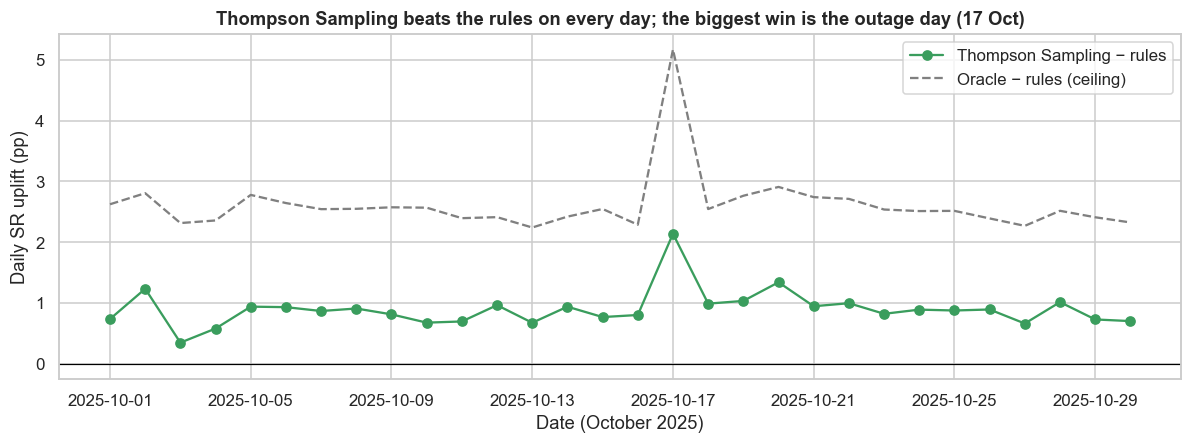

Days TS beat rules: 30 of 30 | daily uplift range +0.35 to +2.14 pp (max on 2025-10-17)
Uplift by payment method (pp):
               ts  oracle
method                   
Card       1.7900  4.0600
Netbanking 0.1000  3.0000
UPI        0.7200  2.0000
Wallet     0.0600  1.2300


In [35]:
# Day-by-day uplift and by-method uplift
dd = pd.DataFrame({"date": sim.timestamp.dt.date, "method": sim.payment_method, "rule": y_r, "ts": y_t, "oracle": outcome["Oracle (upper bound)"]})
day_up = dd.groupby("date")[["rule", "ts", "oracle"]].mean().mul(100)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(pd.to_datetime(day_up.index), day_up.ts - day_up.rule, marker="o", color="#3a9d5d", label="Thompson Sampling − rules")
ax.plot(pd.to_datetime(day_up.index), day_up.oracle - day_up.rule, ls="--", color="grey", label="Oracle − rules (ceiling)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Date (October 2025)"); ax.set_ylabel("Daily SR uplift (pp)")
ax.set_title("Thompson Sampling beats the rules on every day; the biggest win is the outage day (17 Oct)")
ax.legend(); plt.tight_layout(); plt.show()
daily_gain = day_up.ts - day_up.rule
print(f"Days TS beat rules: {(daily_gain > 0).sum()} of {len(daily_gain)} | daily uplift range {daily_gain.min():+.2f} to {daily_gain.max():+.2f} pp (max on {daily_gain.idxmax()})")
print("Uplift by payment method (pp):"); print((dd.groupby("method")[["ts", "oracle"]].mean().sub(dd.groupby("method").rule.mean(), axis=0) * 100).round(2))

**Takeaway:**
- **TS beats the rules on all 30 days** (daily uplift +0.35 to +2.1 pp). The largest gain is on 17 Oct, the outage day.
- **By method**, the gain is concentrated in **cards (+1.8 pp)**, where gateway differences are largest, followed by UPI (+0.7 pp). This matches Juspay's documented pattern of bigger gains in card categories than in UPI.
- **Netbanking and wallets gain almost nothing** (+0.1 pp), although the oracle shows +3.0 pp is available for Netbanking. These segments have low volume, so with a 5.7-hour evidence half-life the bandit never collects enough evidence to separate the gateways. That is the known cost of discounting, and a reason to pool evidence across similar segments in a next version.
- TS captures **0.91 / 2.62 ≈ 35% of the theoretical maximum gain** (the oracle). There is still headroom.
- **Guardrails:** expected median latency +2.7% (999 → 1,026 ms; the limit was +10%); the smallest gateway share is 15.6% (the floor was 5%), so no gateway is starved. **All pre-registered decision criteria are met.**

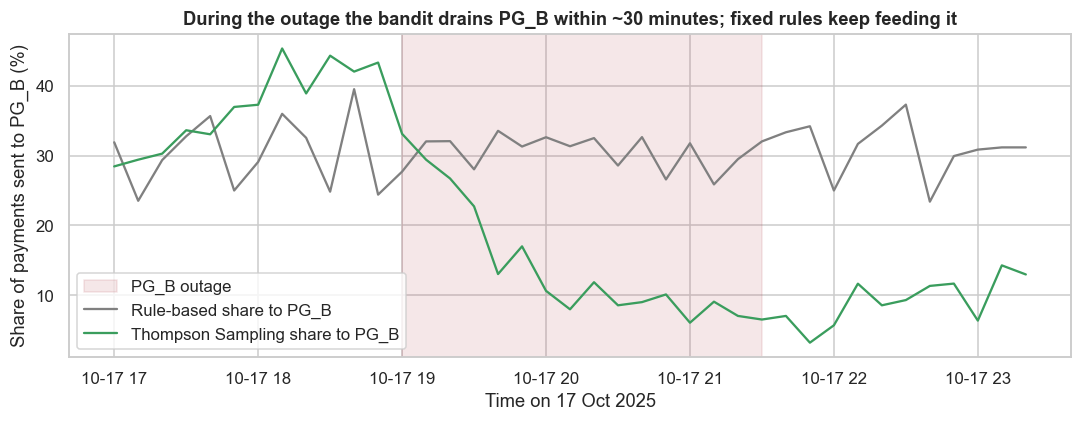

2h before outage  : PG_B share  TS  37.4% | rules  30.5%
first 10 min      : PG_B share  TS  33.1% | rules  27.7%
10-30 min         : PG_B share  TS  28.2% | rules  32.0%
rest of outage    : PG_B share  TS  11.0% | rules  30.4%
2h after recovery : PG_B share  TS   8.6% | rules  31.2%
Payments the rules sent to PG_B during the outage but TS sent elsewhere: 579


In [36]:
# How fast does TS move traffic off PG_B during the outage?
w = pd.DataFrame({"t": sim.timestamp, "pgb_rule": choices["Rule-based (today)"] == 1, "pgb_ts": choices["Thompson Sampling"] == 1})
w = w[(w.t >= o_start - pd.Timedelta(hours=2)) & (w.t < o_end + pd.Timedelta(hours=2))].set_index("t").resample("10min").mean() * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(o_start, o_end, color="#b23a48", alpha=0.12, label="PG_B outage")
ax.plot(w.index, w.pgb_rule, color="grey", label="Rule-based share to PG_B")
ax.plot(w.index, w.pgb_ts, color="#3a9d5d", label="Thompson Sampling share to PG_B")
ax.set_xlabel("Time on 17 Oct 2025"); ax.set_ylabel("Share of payments sent to PG_B (%)")
ax.set_title("During the outage the bandit drains PG_B within ~30 minutes; fixed rules keep feeding it"); ax.legend()
plt.tight_layout(); plt.show()
for lab, lo, hi in [("2h before outage", o_start - pd.Timedelta("2h"), o_start), ("first 10 min", o_start, o_start + pd.Timedelta("10min")),
                    ("10-30 min", o_start + pd.Timedelta("10min"), o_start + pd.Timedelta("30min")), ("rest of outage", o_start + pd.Timedelta("30min"), o_end),
                    ("2h after recovery", o_end, o_end + pd.Timedelta("2h"))]:
    m_ = ((sim.timestamp >= lo) & (sim.timestamp < hi)).to_numpy()
    print(f"{lab:18s}: PG_B share  TS {np.mean(choices['Thompson Sampling'][m_] == 1):6.1%} | rules {np.mean(choices['Rule-based (today)'][m_] == 1):6.1%}")
rerouted = int(((choices["Rule-based (today)"] == 1) & (choices["Thompson Sampling"] != 1) & in_out).sum())
print(f"Payments the rules sent to PG_B during the outage but TS sent elsewhere: {rerouted:,}")

**Takeaway:** before the outage the bandit sent about 37% of traffic to PG_B, the best gateway for SBI, the largest bank. In the first 10 minutes of the outage it barely reacts (33%). By 10–30 minutes it is at 28%, and for the rest of the outage it holds PG_B at about 11%, against a constant ~30% under the fixed rules. During the outage window, SR is **75.3% with TS vs 66.9% with the rules**.

Two honest caveats:
1. **It takes about 30 minutes to react.** That is far slower than Juspay's documented "within a minute", because our bandit has no dedicated downtime detector.
2. **It is slow to come back.** Two hours after recovery, PG_B still gets only about 9% of traffic, because the bad evidence takes hours to fade.

The fix is to pair the bandit with the p-chart alarm from Section 7.7 as a **circuit breaker**: drain fast on an alarm, and reset fast on recovery. That is the two-layer design Juspay documents (a bandit plus a control-theoretic health score).

**Sensitivity of the bandit to its one design knob (the discount γ).** γ was fixed *before* the run at 0.99. We did not tune it (D-1-15). The table shows that the conclusion does not depend on that choice: every reasonable γ beats the rules.

In [37]:
sens = []
for gmm in [0.98, 0.99, 0.995, 0.998]:
    ch = thompson_policy(np.random.default_rng(np.random.SeedSequence(SEED).spawn(3)[2]), gamma=gmm)
    y = (u < P[idx, ch]).astype(int)
    sens.append((gmm, round(np.log(0.5) / np.log(gmm) * 5 / 60, 1), y.mean(), (y.mean() - y_r.mean()) * 100, y[in_out].mean(),
                 (np.bincount(ch, minlength=4) / len(ch)).min()))
pd.DataFrame(sens, columns=["gamma", "evidence half-life (h)", "SR", "uplift vs rules (pp)", "SR in outage", "min gateway share"])

,gamma,evidence half-life (h),SR,uplift vs rules (pp),SR in outage,min gateway share
0,0.9800,2.9000,0.8342,0.6838,0.7812,0.1728
1,0.9900,5.7000,0.8365,0.9135,0.7532,0.1556
2,0.9950,11.5000,0.8393,1.1918,0.7545,0.1267
3,0.9980,28.9000,0.8431,1.5704,0.7428,0.1104


## 9. Business Translation — from SR uplift to ₹ GMV recovered

**Step-by-step logic:**
1. Extra successful payments = payments TS saved − payments TS lost (the discordant pairs, counted directly in the replay).
2. GMV recovered (gross) = ₹ value of payments TS saved − ₹ value of payments TS lost. We use the **actual order amounts**, not an average.
3. Not every failed payment is lost revenue: some customers **retry** and succeed anyway. Net GMV recovered = gross × (1 − retry-recovery rate).
4. Scale to a portfolio: the result per 1 crore monthly payments, assuming the same mix.

**Assumptions** (D-1-17): retry-recovery rate base 50% (best 30%, worst 70%). This is not documented in the case file and is our assumption. Uplift: **base** = our replay (+0.91 pp); **best** = the upper paired 95% CI bound; **worst** = **Juspay's documented real-world 21-day gain of 0.59 pp** (83.19% − 82.60%). We use the documented figure rather than our lower CI bound because the twin's CI only reflects sampling noise. It does not cover the risk that our simulated gateway differences are larger than reality. Orchestrator take rate on GMV is 0.15% (illustrative, only to show orchestrator revenue).

In [38]:
amt = sim.amount_inr.to_numpy()
saved = (y_r == 0) & (y_t == 1); lost = (y_r == 1) & (y_t == 0)
gross_gmv = amt[saved].sum() - amt[lost].sum()
extra_txn = saved.sum() - lost.sum()
gmv_per_extra = gross_gmv / extra_txn
n_month = len(sim)
uplift = d.mean()
scen = pd.DataFrame({
    "scenario": ["Worst", "Base", "Best"],
    "SR uplift (pp)": [0.59, uplift * 100, paired_ci[1] * 100],      # worst = Juspay documented 83.19 - 82.60
    "retry-recovery rate": [0.70, 0.50, 0.30],
})
scen["extra successful payments / month"] = scen["SR uplift (pp)"] / 100 * n_month
scen["gross GMV recovered ₹ / month"] = scen["extra successful payments / month"] * gmv_per_extra
scen["net GMV recovered ₹ / month"] = scen["gross GMV recovered ₹ / month"] * (1 - scen["retry-recovery rate"])
scen["net GMV ₹ per 1 crore payments / month"] = scen["net GMV recovered ₹ / month"] / n_month * 1e7
scen["orchestrator revenue ₹ per 1 crore payments / month (0.15%)"] = scen["net GMV ₹ per 1 crore payments / month"] * 0.0015
print(f"Replay: {saved.sum():,} payments saved, {lost.sum():,} lost -> {extra_txn:,} extra successes; gross GMV ₹{gross_gmv:,.0f}")
print(f"Average value of a recovered payment: ₹{gmv_per_extra:,.0f}")
out_gmv = amt[saved & in_out].sum() - amt[lost & in_out].sum()
print(f"Of which during the 2.5-hour PG_B outage: {int((saved & in_out).sum() - (lost & in_out).sum()):,} payments, ₹{out_gmv:,.0f} gross GMV")
scen.set_index("scenario").T.round(2)

Replay: 6,836 payments saved, 3,006 lost -> 3,830 extra successes; gross GMV ₹8,204,302
Average value of a recovered payment: ₹2,142
Of which during the 2.5-hour PG_B outage: 187 payments, ₹193,706 gross GMV


scenario,Worst,Base,Best
SR uplift (pp),0.5900,0.9100,0.9600
retry-recovery rate,0.7000,0.5000,0.3000
extra successful payments / month,"2,473.6800","3,830.0000","4,024.1000"
gross GMV recovered ₹ / month,"5,298,910.6200","8,204,302.0200","8,620,086.0800"
net GMV recovered ₹ / month,"1,589,673.1900","4,102,151.0100","6,034,060.2500"
net GMV ₹ per 1 crore payments / month,"37,915,442.7600","97,840,784.6500","143,918,931.4100"
orchestrator revenue ₹ per 1 crore payments / month (0.15%),"56,873.1600","146,761.1800","215,878.4000"


**Business reading:**
- **Base case:** dynamic routing recovers about **3,830 extra successful payments a month** in this merchant group, worth **₹82 lakh** of gross order value (≈ ₹2,140 per recovered payment). Allowing for the half of those customers who would have retried successfully anyway, that is **≈ ₹41 lakh net GMV a month (≈ ₹4.9 crore a year)**.
- **Range:** ≈ ₹16 lakh a month (worst: Juspay's documented 0.59 pp gain and 70% retry recovery) to ≈ ₹60 lakh (best).
- **At portfolio scale:** per 1 crore payments a month, base ≈ **₹9.8 crore net GMV a month** (range ₹3.8–14.4 crore).
- **Who benefits:** the orchestrator's own revenue on that GMV at an illustrative 0.15% take is only ≈ ₹1.5 lakh per crore payments. The real prize is the *merchant's* recovered sales, so the business case is merchant retention and win-rate, not take-rate.
- **Where the value comes from:** only ≈ ₹1.9 lakh of the gain is from the single outage. Most of it comes from everyday, segment-level routing (cards and SBI/HDFC traffic).

If we roll this out, I expect an SR uplift between Juspay's documented 0.6 pp and our simulated 0.9 pp. The exact figure must come from the live A/B test.

## 10. Recommendation and Decision

**Decision against the pre-registered rule (Section 3):** (i) McNemar p < 0.001 ✅; (ii) lower 95% CI bound of the uplift = +0.87 pp > 0 ✅; (iii) median latency +2.7% (< 10%) and smallest gateway share 15.6% (> 5%) ✅. **All criteria are met on the simulation.** Because the data is synthetic, the decision is to **run a live test**, not to switch everyone over immediately.

**I recommend a staged move to dynamic routing, with fixed rules kept as the fallback:**

| Stage | When | Action | Exit criterion |
|---|---|---|---|
| 1. Quick wins | Week 0 | Hard-code the 4 Holm-confirmed segment rules (SBI UPI & cards → PG_B; HDFC & ICICI netbanking → PG_C). Open a commercial review with PG_D on card authentication (21.8% vs ≈ 12% authentication-failure rate) or pilot an authentication/authorisation flow split. | SR of those segments up, with no latency regression |
| 2. Outage protection | Weeks 1–2 | Deploy the p-chart: Rule 1 pages on-call, Rule 2 shifts traffic automatically. Use hour-of-day baselines. Wire the alarm into the router as a circuit breaker. | Fewer than 1 false alarm a day; detection within 15 minutes |
| 3. Live A/B test | Weeks 3–4 | Random 50/50 split by customer session: rules vs bandit, **14 days, ≥ 89k payments per arm**, one pre-registered read at the end (or the |Z| > 2.74 sequential threshold if daily monitoring is mandatory). | Lower 95% CI of the uplift > 0 and guardrails hold |
| 4. Roll-out | Week 5+ | Ramp 50% → 80% → 100% per merchant cohort. Keep a **permanent 5–10% rules holdout** to keep measuring the uplift. Offer it opt-in per merchant (Juspay: "95%+ merchants use rule-based ordering"). | Holdout uplift stays positive month on month |

**KPIs to monitor after launch:** SR overall and by method × bank (with Wilson CIs); uplift vs the holdout (monthly, with CI); net GMV recovered per month; traffic share per gateway (floor 5%); median and p95 latency; authentication-failure share on cards; alarms per day and minutes-to-detect; gateway cost per successful payment.

## 11. Risks, Limitations and Next Steps

**Limits of synthetic data.**
- The **effect sizes are ours**, calibrated to Juspay's published averages. The *direction* of the conclusions (segment-specific winners, the outage benefit, the peeking danger) is robust. The *exact* uplift is not a forecast for any real merchant.
- The digital twin **knows the true success probabilities**. Real routing never gets this. Outcomes arrive late, some are "pending" for minutes, and success depends on things we did not model (card BIN, device, app version, merchant-specific integrations).
- **Independence:** real customers retry, so one customer's attempts are correlated. That makes true CIs somewhat wider than ours. In real data, cluster standard errors by customer or session.
- **Stationarity:** our gateway quality is fixed apart from the outage and festive load. Real gateways drift, which makes discounting *more* valuable, but also makes any single 30-day estimate stale.

**Operational risks.**
- **Concentration:** a bandit may push most of a segment's traffic to one gateway, creating a dependency and commercial pressure. Mitigation: a 5% minimum share per gateway, with volume commitments honoured.
- **Cost blindness:** TS here maximises SR only. PG_D is cheaper, so the real objective should be *expected margin* = SR × (MDR − gateway fee).
- **Feedback loops / starvation:** if exploration is too low, recovered gateways stay unused. Monitor each gateway's share and its posterior uncertainty.

**What real data would change.** Real logs would give BIN-level contexts, true retry behaviour (to replace the 50% assumption), gateway pricing, and genuine drift. We would then (1) run the 14-day A/B test sized in 7.4, (2) report per-merchant uplift with cluster-robust CIs, and (3) re-estimate the ₹ impact from real recovered-payment amounts.

**Next steps.** Fit p-chart baselines by hour of day to cut night-time false alarms; add CUSUM/EWMA charts for faster detection of *gradual* degradation; extend the bandit to authentication-vs-authorisation flow splitting (Cashfree pattern) for cards on PG_D.

## 12. Appendix

**Formulas used**

| Quantity | Formula |
|---|---|
| Success rate | SR = successes / attempts |
| Wilson 95% CI | (p̂ + z²/2n ± z·√(p̂(1−p̂)/n + z²/4n²)) / (1 + z²/n), z = 1.96 |
| Two-proportion Z | Z = (p̂₁ − p̂₂) / √(p̄(1−p̄)(1/n₁ + 1/n₂)), p̄ = pooled SR |
| Cohen's h | h = 2·arcsin√p₁ − 2·arcsin√p₂ |
| Chi-square | χ² = Σ (O − E)² / E, E = row total × column total / N |
| Cramér's V | V = √(χ² / (N·(min(r, c) − 1))) |
| Sample size per arm | n = 2·(z₁₋α/₂ + z₁₋β)² / h² (equivalently (z₁₋α/₂√(2p̄q̄) + z₁₋β√(p₁q₁+p₂q₂))² / (p₁−p₂)²) |
| Holm step-down | sort p₍₁₎ ≤ … ≤ p₍ₘ₎; reject while p₍ᵢ₎ ≤ α/(m − i + 1) |
| p-chart limits | p̄ ± 3·√(p̄(1−p̄)/nₜ) |
| McNemar | χ² = (|b − c| − 1)² / (b + c), b, c = discordant pairs |
| Thompson Sampling | draw θ_g ~ Beta(α_g, β_g) per gateway; pick argmax θ_g; α += success, β += failure; discount α, β by γ each batch |
| GMV recovered | Σ amount(saved) − Σ amount(lost), × (1 − retry-recovery rate) |

**Glossary (simple English)**

| Term | Meaning |
|---|---|
| Success rate (SR) | Share of payment attempts that went through. |
| Binomial proportion | A rate built from yes/no outcomes, like SR. |
| p-value | How surprising the data would be if there were truly no difference. Below 0.05 we call it "significant". |
| Confidence interval | The range of plausible values for the true number. |
| Wilson interval | A more reliable CI for rates, especially for small samples or rates near 0% or 100%. |
| Effect size (Cohen's h, Cramér's V) | *How big* a difference or association is, regardless of sample size. |
| Statistical power | The chance a test detects a real effect of a given size. |
| MDE | The smallest real effect a test can reliably detect. |
| Multiple testing | Running many tests, which raises the chance of a lucky false positive. |
| Holm–Bonferroni | A correction that keeps the chance of *any* false positive at 5% across many tests. |
| Confounding / Simpson's paradox | A hidden third factor (here: payment-method mix) distorts a comparison; overall and within-group results can disagree. |
| Mantel–Haenszel test | Compares two groups *within* strata, then pools the results, removing the confounder's effect. |
| Interaction | The effect of one factor (gateway) depends on another (bank). |
| Likelihood-ratio test | Compares a simpler and a richer model to see whether the extra terms genuinely help. |
| Peeking | Checking an experiment repeatedly and stopping at the first good-looking result, which inflates false positives. |
| p-chart | A control chart for rates. It flags windows that fall outside normal variation. |
| Multi-armed bandit / Thompson Sampling | A learning router that balances trying options (explore) with using the best one (exploit). |
| McNemar test | A test for paired yes/no outcomes that looks only at the cases where the two methods disagree. |
| Digital twin | A simulation model of the system, used to compare policies safely offline. |
| GMV | Gross merchandise value: the ₹ value of successful orders. |